# LAB 01 | APPSTAT
## Статистический анализ дефектов полупроводниковых пластин

**Датасет:** WM-811K (карты дефектности кремниевых пластин)

---

Команда: инфохимики - Демина Александра, ИСУ 504844, Козлова Дарья ИСУ:504686
дизайнеры - Аблязизова Ева ИСУ:504459, Курнакова Валерия, ИСУ 466435

**Исследовательский вопрос:** связаны ли количества дефектных чипов в центральной и краевой зонах пластины? В выборке из 15 881 пластины выявлена слабая положительная корреляция (коэффициент Спирмена ≈ 0,27).


## Содержание

- [01. Первый спринт. Исследование случайных величин](#scrollTo=801f44e0)
  - [01.0. Данные исследования](#scrollTo=7330897d)
  - [01.1. Дефекты в центре пластины](#scrollTo=073c2714)
    - [01.1.1. Описание случайной величины](#scrollTo=99a247c9)
    - [01.1.2. Распределение числа дефектов](#scrollTo=02aca094)
    - [01.1.3. Состоятельность среднего и сравнение выборок](#scrollTo=ed41ed8f)
    - [01.1.4. Выводы](#scrollTo=6063215b)
  - [01.2. Дефекты у края пластины](#scrollTo=e19102cb)
    - [01.2.1. Как определили краевую зону](#scrollTo=60dc3ba8)
    - [01.2.2. Случайность: разброс внутри лотов](#scrollTo=a266000a)
    - [01.2.3. Распределение числа дефектов](#scrollTo=6754663b)
    - [01.2.4. Описательные статистики](#scrollTo=c22821f9)
    - [01.2.5. Подгонка распределений](#scrollTo=585905fd)
    - [01.2.6. Сравнение моделей с данными](#scrollTo=3e8fcf95)
    - [01.2.7. Нормализация](#scrollTo=a30965dc)
    - [01.2.8. Формулы распределений](#scrollTo=0862a925)
    - [01.2.9. Проверка оценок на выборках](#scrollTo=966e1a1e)
    - [01.2.10. Состоятельность оценок](#scrollTo=bf9720ae)
    - [01.2.11. Выборки с возвращением и без](#scrollTo=621e9b17)
    - [01.2.12. Проверка гипотез](#scrollTo=56861d89)
    - [01.2.13. Сводная таблица](#scrollTo=21e17561)
    - [01.2.14. Выводы](#scrollTo=2c2259bf)
  - [01.3. Связь числа дефектов в центре и у края](#scrollTo=70a65849)
  - [01.4. Смещение центра дефектов](#scrollTo=9c2eae0c)
    - [01.4.1. Что измеряем](#scrollTo=74545b81)
    - [01.4.2. Разброс внутри партий](#scrollTo=327a59cc)
    - [01.4.3. Распределение смещения](#scrollTo=6f546ed8)
    - [01.4.4. Описательные статистики](#scrollTo=560a6660)
    - [01.4.5. Сравнение трёх моделей](#scrollTo=a931f1b1)
    - [01.4.6. Модель равномерных дефектов](#scrollTo=2836b762)
    - [01.4.7. Модели распределения](#scrollTo=fed1d878)
    - [01.4.8. Преобразования шкалы](#scrollTo=4e7fa785)
    - [01.4.9. Проверка оценок на выборках](#scrollTo=934cc5b6)
    - [01.4.10. Состоятельность оценок](#scrollTo=e1a4ecbb)
    - [01.4.11. Выборки с возвращением и без](#scrollTo=2522c543)
    - [01.4.12. Проверка гипотез](#scrollTo=7f4df223)
    - [01.4.13. Сводная таблица результатов](#scrollTo=15172186)
    - [01.4.14. Выводы](#scrollTo=ef38f7f8)
  - [01.5. Выводы первого спринта](#scrollTo=ac6153c9)
  - [01.6. cat_mark_table](#scrollTo=c45ac67d)
- [02. Второй спринт. Генератор случайных чисел](#scrollTo=9aec5070)
  - [02.1. Генератор смещения центра дефектов](#scrollTo=09609ef9)
    - [Формула генератора](#scrollTo=5a8b90fff112)
    - [Графики и метрики](#scrollTo=6ecd79117445)
    - [Проверка одного числа](#scrollTo=9ec3810d4184)
  - [02.2. cat_mark_table](#scrollTo=43fba8feff0e)
- [Источники](#scrollTo=629742299d02)


<a id="appstat-sprint1"></a>

## 01. Первый спринт. Исследование случайных величин


<a id="appstat-data"></a>

### 01.0. Данные исследования


**Единицы измерения и шкалы графиков.** `n_center` и `n_edge` — число дефектных чипов на пластину (шт.); `r_def` — нормированное смещение центра дефектов (доля нормирующего радиуса, безразмерная величина). Стандартизованная величина `z` и другие преобразования показаны в новой безразмерной шкале. В графиках используются разные показатели по оси ординат: *число пластин*, *доля пластин* и *плотность вероятности*; их значения имеют различный смысл.


Расчёты выполняются по таблице признаков `wm811k_features.parquet`, встроенной в ноутбук для воспроизводимости исследования.


In [1]:
# @title Загрузка встроенной таблицы
import pandas as pd

from base64 import b64decode
from io import BytesIO

# Встроенная копия wm811k_features.parquet.
DATA_BASE64 = (
    "..."
)
df = pd.read_parquet(BytesIO(b64decode(DATA_BASE64)))
x = df["n_center"]
N = len(x)

print("пластин:", N, "| dieSize:", df["dieSize"].iloc[0])
print("среднее:", x.mean(), "| дисперсия:", x.var(ddof=1))
print("доля нулей:", (x == 0).mean(), "| max:", x.max())

пластин: 15881 | dieSize: 516.0
среднее: 22.964800705245263 | дисперсия: 37.41179619611033
доля нулей: 0.0 | max: 58


In [2]:
# @title Настройки графиков
import matplotlib.pyplot as plt
from cycler import cycler

SPACE_COLORS = {
    "bg_fig": "#050816",
    "bg_ax": "#0B1730",
    "edge": "#8EA3D8",
    "text": "#EAF2FF",
    "ticks": "#B8C7FF",
    "grid": "#24365F",
    "cyan": "#49D6FF",
    "teal": "#5CE1E6",
    "violet": "#8B5CF6",
    "magenta": "#FF4ECD",
    "gold": "#FFCD78",
    "mint": "#63F5D2",
    "soft": "#AEEBFF"
}

plt.rcParams.update({
    "figure.facecolor": SPACE_COLORS["bg_fig"],
    "savefig.facecolor": SPACE_COLORS["bg_fig"],
    "axes.facecolor": SPACE_COLORS["bg_ax"],
    "axes.edgecolor": SPACE_COLORS["edge"],
    "axes.labelcolor": SPACE_COLORS["text"],
    "axes.titlecolor": SPACE_COLORS["text"],
    "axes.titleweight": "semibold",
    "text.color": SPACE_COLORS["text"],
    "xtick.color": SPACE_COLORS["ticks"],
    "ytick.color": SPACE_COLORS["ticks"],
    "grid.color": SPACE_COLORS["grid"],
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
    "axes.prop_cycle": cycler(
        color=[SPACE_COLORS["cyan"], SPACE_COLORS["violet"], SPACE_COLORS["magenta"], SPACE_COLORS["mint"], SPACE_COLORS["gold"]]
    ),
    "figure.figsize": (9, 5),
    "figure.dpi": 110
})

def style_axis(ax, grid=True):
    if grid:
        ax.grid(True)
    for spine in ax.spines.values():
        spine.set_alpha(0.95)


def style_probplot(ax, point_color=None, line_color=None):
    point_color = point_color or SPACE_COLORS["violet"]
    line_color = line_color or SPACE_COLORS["magenta"]
    style_axis(ax)
    lines = ax.get_lines()
    if len(lines) >= 1:
        lines[0].set_color(point_color)
        lines[0].set_markerfacecolor(point_color)
        lines[0].set_markeredgecolor(point_color)
        lines[0].set_markersize(4.5)
        lines[0].set_alpha(0.9)
    if len(lines) >= 2:
        lines[1].set_color(line_color)
        lines[1].set_linewidth(1.8)
        lines[1].set_alpha(0.95)


def color_hist(ax, face=None, edge=None):
    face = face or SPACE_COLORS["cyan"]
    edge = edge or SPACE_COLORS["soft"]
    for patch in ax.patches:
        patch.set_facecolor(face)
        patch.set_edgecolor(edge)
        patch.set_alpha(0.95)
    style_axis(ax)


<a id="appstat-center"></a>

### 01.1. Дефекты в центре пластины


#### 01.1.1. Описание случайной величины

При случайном выборе одной пластины из 15 881 наблюдений величина `n_center` определяется как число дефектных чипов в центральной зоне ($r<0{,}5$). Каждая пластина содержит 516 чипов. Радиус $r$ измеряется в долях расстояния до самого дальнего чипа.

Одинаковый размер пластин не задаёт число дефектов: в центре встречается от 5 до 58. Поэтому до выбора пластины её счётчик неизвестен. Для описания распределения рассматривается модель Пуассона; соответствие модели проверяется по наблюдаемому разбросу.


#### 01.1.2. Распределение числа дефектов


count    15881.000000
mean        22.964801
std          6.116518
min          5.000000
25%         19.000000
50%         23.000000
75%         27.000000
max         58.000000
Name: n_center, dtype: float64
асимметрия: 0.4436329678497521 эксцесс: 0.46088267833752194
дисперсия/среднее: 1.6290930052602333


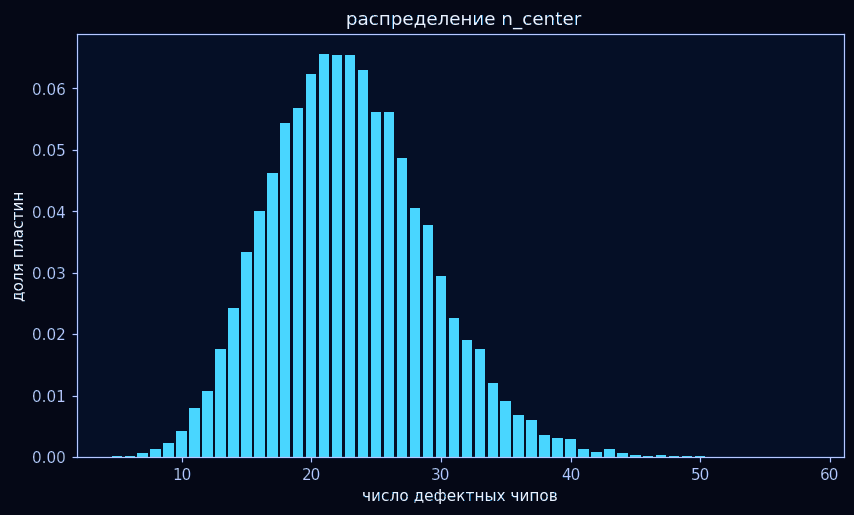

In [3]:
# @title Построение распределения n_center
##EDA
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

xv = x.to_numpy()
print(x.describe())
print("асимметрия:", stats.skew(xv), "эксцесс:", stats.kurtosis(xv))
print("дисперсия/среднее:", x.var(ddof=1) / x.mean())

vals, cnt = np.unique(xv, return_counts=True)
fig, ax = plt.subplots(figsize=(9.2, 5))
ax.bar(vals, cnt / N, color=SPACE_COLORS["cyan"], edgecolor=SPACE_COLORS["soft"], linewidth=0.5)
ax.set_xlabel("число дефектных чипов")
ax.set_ylabel("доля пластин")
ax.set_title("Распределение n_center")
style_axis(ax)
plt.show()


В изученном наборе от 5 до 58 дефектных чипов в центре на пластину. Среднее — 22,96 чипа, дисперсия — 37,41 чипа². Отношение дисперсии к среднему равно 1,63. Асимметрия положительная (0,44), то есть правый хвост длиннее.


среднее z: -3.1498147848064386e-16 | std z: 1.0


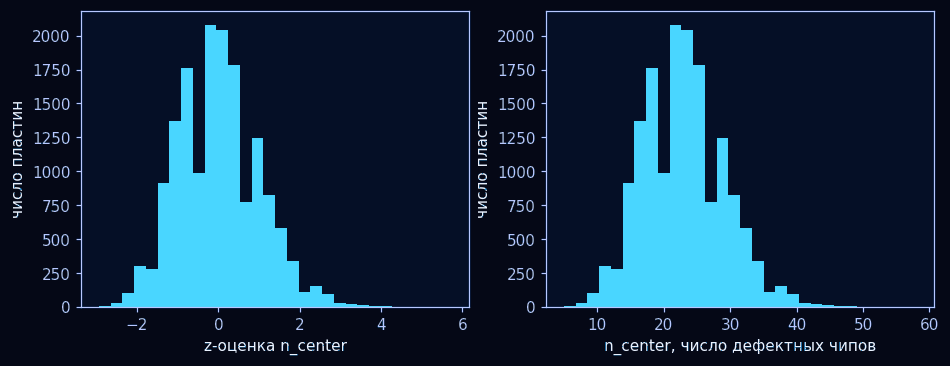

In [4]:
# @title Показать код
z = (x - x.mean()) / x.std(ddof=1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(z, bins=30, color=SPACE_COLORS["cyan"], edgecolor=SPACE_COLORS["soft"])
ax[0].set_xlabel("z-оценка n_center")
ax[0].set_ylabel("число пластин")
style_axis(ax[0])
ax[1].hist(x, bins=30, color=SPACE_COLORS["violet"], edgecolor=SPACE_COLORS["soft"])
ax[1].set_xlabel("n_center, число дефектных чипов")
ax[1].set_ylabel("число пластин")
style_axis(ax[1])
plt.show()

print("среднее z:", z.mean(), "| std z:", z.std(ddof=1))


Для стандартизации используется преобразование $z = (x - \bar{x})/s$: среднее стандартизованной величины равно 0, стандартное отклонение — 1. Это убирает единицы измерения и делает величину сопоставимой с другими, а также удобно для сравнения с нормальным распределением. Форма распределения при этом не меняется: график $z$ повторяет гистограмму $n\_center$ с другой шкалой.


**Интерпретация стандартизации.** Ноль на новой шкале — это среднее число дефектов, а не пластина без дефектов. Правый хвост остался на месте. Значит, смена шкалы сама по себе не делает распределение нормальным.


In [5]:
# @title Показать код
mean, var = x.mean(), x.var(ddof=1)
D = (N - 1) * var / mean
p_over = stats.chi2.sf(D, N - 1)
print(f"var/mean = {var/mean:.3f}, статистика = {D:.1f}, p = {p_over:.3g}")

var/mean = 1.629, статистика = 25870.0, p = 0


Проверка перерассеяния дала $D=25870$ и отношение $s^2/\bar{x}=1{,}629$. Вывод программы округляет крайне малое $p$ до нуля. Результат указывает на перерассеяние в исследуемых данных.


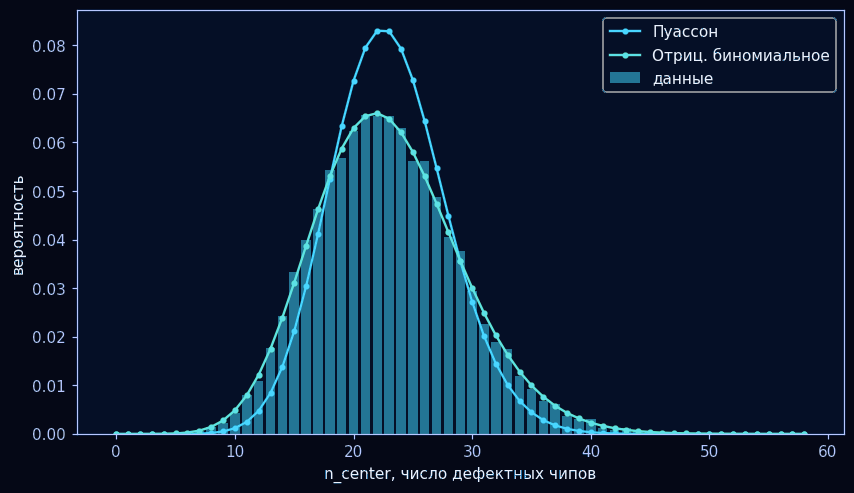

In [6]:
# @title Показать код
pois = stats.poisson(mean)
p_nb = mean / var
r_nb = mean * p_nb / (1 - p_nb)
nb = stats.nbinom(r_nb, p_nb)
fits = {"Пуассон": (pois, 1), "Отриц. биномиальное": (nb, 2)}

kk = np.arange(0, int(xv.max()) + 1)
emp = np.bincount(xv.astype(int), minlength=len(kk)) / N
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.bar(kk, emp, alpha=0.5, color=SPACE_COLORS["cyan"], edgecolor=SPACE_COLORS["soft"], label="данные")
for name, (dist, _) in fits.items():
    ax.plot(kk, dist.pmf(kk), "o-", markersize=3.5, linewidth=1.5, label=name)
ax.set_xlabel("n_center, число дефектных чипов")
ax.set_ylabel("вероятность")
ax.legend()
style_axis(ax)
plt.show()


In [7]:
# @title Показать код
def gof_chi2(x, dist, n_params, min_exp=5):
    xi = x.astype(int)
    kmax = int(xi.max())
    ks = np.arange(kmax + 1)
    o = list(np.bincount(xi, minlength=kmax + 1).astype(float))
    e = list(len(xi) * dist.pmf(ks))
    e[-1] += len(xi) * dist.sf(kmax)
    while len(e) > 2 and e[-1] < min_exp:
        le, lo = e.pop(), o.pop(); e[-1] += le; o[-1] += lo
    while len(e) > 2 and e[0] < min_exp:
        fe, fo = e.pop(0), o.pop(0); e[0] += fe; o[0] += fo
    chi2, p = stats.chisquare(o, e, ddof=n_params)
    return chi2, p, len(o)

for name, (dist, npar) in fits.items():
    chi2, p, bins = gof_chi2(xv, dist, npar)
    print(f"{name}: chi2 = {chi2:.1f}, ячеек = {bins}, p = {p:.3g}")

Пуассон: chi2 = 3765.5, ячеек = 33, p = 0
Отриц. биномиальное: chi2 = 62.9, ячеек = 43, p = 0.0118


##### 01.1.2.1. Распределение Пуассона

Дискретная величина $X$ имеет распределение Пуассона с параметром $\lambda>0$, если

$$P(X=k)=\frac{\lambda^k e^{-\lambda}}{k!},\quad k=0,1,2,\dots$$

Среднее и дисперсия равны: $\mathbb{E}[X]=\operatorname{Var}(X)=\lambda$. Распределение возникает как предел биномиального при $n\to\infty$, $p\to 0$, $np=\lambda$, то есть описывает число редких независимых событий.

##### 01.1.2.2. Отрицательное биномиальное распределение

$$P(X=k)=\binom{k+r-1}{k}p^r(1-p)^k,\quad k=0,1,2,\dots$$

Среднее $\mu = r(1-p)/p$, дисперсия $\sigma^2=\mu/p>\mu$. Оно получается как смесь пуассоновских распределений, у которых интенсивность $\lambda$ сама случайна и распределена по гамма-закону. Поэтому подходит для данных, где дисперсия больше среднего. По методу моментов: $p=\bar{x}/s^2$, $r=\bar{x}p/(1-p)$.

Наблюдаемая дисперсия превышает среднее, что указывает на перерассеяние по сравнению с моделью Пуассона. Результаты проверки гипотезы о согласии с распределением Пуассона приведены выше.


#### 01.1.3. Состоятельность среднего и сравнение выборок


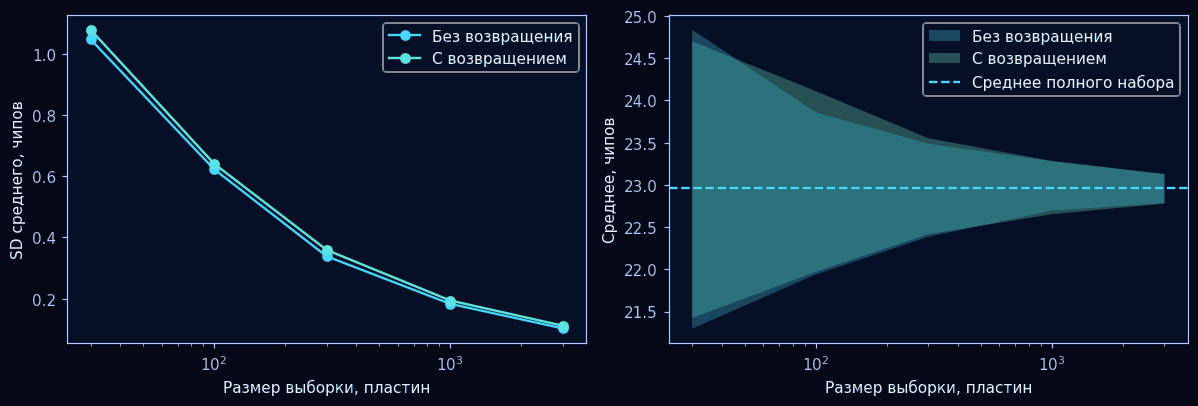

,n,"Среднее, чипов","Медиана, чипов","Дисперсия, чипов²"
Весь набор,15881.0,22.965,23.0,37.412
С возвращением,1000.0,22.886,23.0,42.031
Без возвращения,1000.0,22.907,22.0,38.433


In [8]:
# @title Устойчивость среднего и сравнение выборок
center_values = df["n_center"].to_numpy()
center_rng = np.random.default_rng(42)
sizes = [30, 100, 300, 1000, 3000]
full_mean = center_values.mean()
rows = []
for size in sizes:
    for replace, label in [(True, "С возвращением"), (False, "Без возвращения")]:
        means = np.array([center_rng.choice(center_values, size, replace=replace).mean()
                          for _ in range(200)])
        lower, upper = np.quantile(means, [0.05, 0.95])
        rows.append([size, label, means.std(ddof=1), lower, upper])
center_check = pd.DataFrame(rows, columns=["n", "Отбор", "SD", "q05", "q95"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, group in center_check.groupby("Отбор"):
    axes[0].plot(group["n"], group["SD"], "o-", linewidth=1.8, label=label)
    axes[1].fill_between(group["n"].to_numpy(), group["q05"].to_numpy(),
                         group["q95"].to_numpy(), alpha=0.18, label=label)
axes[0].set(xscale="log", xlabel="Размер выборки, пластин", ylabel="SD среднего, чипов")
axes[1].axhline(full_mean, linestyle="--", color=SPACE_COLORS["gold"], linewidth=1.6, label="Среднее полного набора")
axes[1].set(xscale="log", xlabel="Размер выборки, пластин", ylabel="Среднее, чипов")
for ax in axes:
    ax.legend()
    style_axis(ax)
plt.tight_layout()
plt.show()
samples = {
    "Весь набор": center_values,
    "С возвращением": center_rng.choice(center_values, 1000, replace=True),
    "Без возвращения": center_rng.choice(center_values, 1000, replace=False),
}


**Состоятельность среднего.** Левый график показывает разброс средних по повторным выборкам, правый — сужение полосы вокруг среднего полного набора при увеличении объёма выборки. В двух отдельных выборках по 1000 пластин получили 22,89 и 22,91 чипа при среднем по всему набору 22,96. Это один пример, а тенденцию видно по повторным выборкам.


#### 01.1.4. Выводы

Среднее число дефектов в центре — 22,96, дисперсия — 37,41. Разброс больше, чем предполагает модель Пуассона. По сохранённым результатам теста согласия при уровне значимости 5% гипотезу согласия отвергаем и для отрицательной биномиальной модели ($p=0{,}0118$). Причину перерассеяния по этому тесту установить нельзя.


<a id="appstat-edge"></a>

### 01.2. Дефекты у края пластины


#### 01.2.1. Как определили краевую зону

Каждая пластина в датасете — это матрица, где каждая клетка соответствует позиции на сетке:

- 0 — позиция вне пластины (чипа нет)
- 1 — годный чип
- 2 — дефектный чип

Для каждой пластины делим расстояние от чипа до центра $(i_c,j_c)$ на максимальное расстояние от центра до чипа:

$$r_{ij}=\frac{\sqrt{(i-i_c)^2+(j-j_c)^2}}{\max d}$$

Тогда $r\in[0,1]$: 0 — центр пластины, 1 — самый дальний от центра чип.

n_edge — число дефектных чипов у края, где край — это чипы с $r > 0.8$.

**Какие пластины вошли в анализ** 

WM-811K, Wu et al. 2015. 811 457 карт пластин с реального производства. Эксперты разметили около 20% карт по 9 классам: 8 типов паттернов брака и класс none (паттерна нет). 

Для работы данные отфильтрованы:
- класс none — в разметке не выделен один из восьми типов рисунка дефектов;
- dieSize = 516 (самое частое значение) — dieSize это число чипов на пластине, поэтому у всех оставшихся пластин одинаковая сетка и счётчики дефектов можно сравнивать напрямую.

| Показатель | Значение |
|---|---|
| Пластин после фильтра | 15881 |
| Лотов | 715 |
| Пластин на лот в среднем | ≈ 22 |
| Чипов на пластине | 516 |
| Чипов в краевой зоне (r > 0.8) | 186 (оценка по площади) |


In [9]:
# @title Показать код
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
import statsmodels.api as sm

# константы
SEED = 42
N_REP = 100        # повторов на размер выборки (состоятельность)
N_SAMPLE = 1000    # размер выборки с возвращением / без
N_MC = 500         # повторов Монте-Карло для sd среднего
B_BOOT = 300       # повторов параметрического бутстрапа
R_CENTER = 0.5     # пороги зон из src/features.py
R_EDGE = 0.8

rng = np.random.default_rng(SEED)

In [10]:
# @title Показать код
x = df["n_edge"]
print("df.shape =", df.shape)
print("n =", len(x))
print("dieSize =", df["dieSize"].iloc[0], "| уникальных dieSize:", df["dieSize"].nunique())
print("failureType:", df["failureType"].unique().tolist())
print("число лотов =", df["lotName"].nunique())
x.describe()

df.shape = (15881, 11)
n = 15881
dieSize = 516.0 | уникальных dieSize: 1
failureType: ['none']
число лотов = 715


count    15881.000000
mean        41.869719
std          7.803173
min         16.000000
25%         36.000000
50%         41.000000
75%         47.000000
max         79.000000
Name: n_edge, dtype: float64

#### 01.2.2. Случайность: разброс внутри лотов

Край определяем одинаково на всех пластинах, а число дефектов у края меняется даже внутри одной партии. Посмотрим на этот разброс, прежде чем подбирать модель.


In [11]:
# @title Показать код
by_lot = df.groupby("lotName")["n_edge"].agg(["count", "min", "max", "mean", "std"])
by_lot[by_lot["count"] >= 10].head(10)

,count,min,max,mean,std
lotName,,,,,
lot42869,23,34,60,45.347826,7.003951
lot42870,25,32,61,45.360000,7.088018
lot42871,21,32,52,44.095238,5.494586
lot42872,23,30,53,42.565217,5.883923
lot42873,21,35,57,45.571429,6.376295
lot42874,24,27,58,45.250000,7.825543
lot42875,23,31,59,44.173913,5.843817
lot42876,23,29,62,44.913043,7.627183
lot42877,25,31,65,43.880000,7.584634


In [12]:
# @title Показать код
# разложение дисперсии: внутри лотов и между лотами
g = df.groupby("lotName")["n_edge"]
var_within = (g.var(ddof=1).fillna(0) * (g.size() - 1)).sum() / (len(df) - g.ngroups)
var_between = g.mean().var(ddof=1)
icc = var_between / (var_between + var_within)
pd.Series({"дисперсия всей выборки": x.var(ddof=1),
           "внутрилотовая компонента": var_within,
           "межлотовая компонента": var_between,
           "ICC": icc}).round(4)

дисперсия всей выборки      60.8895
внутрилотовая компонента    53.4556
межлотовая компонента        9.7931
ICC                          0.1548
dtype: float64

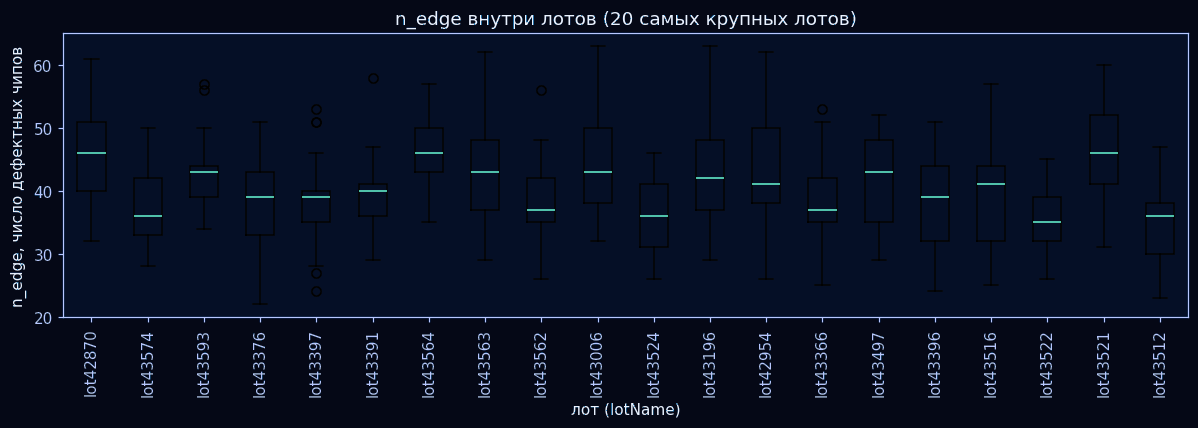

In [13]:
# @title Показать код
# n_edge по 20 самым крупным лотам
top = df["lotName"].value_counts().head(20).index
data = [df.loc[df["lotName"] == lot, "n_edge"].values for lot in top]
fig, ax = plt.subplots(figsize=(11, 4))
bp = ax.boxplot(data, patch_artist=True)
for box in bp['boxes']:
    box.set(facecolor=SPACE_COLORS["cyan"], edgecolor=SPACE_COLORS["soft"], alpha=0.55)
for med in bp['medians']:
    med.set(color=SPACE_COLORS["magenta"], linewidth=1.6)
for w in bp['whiskers'] + bp['caps']:
    w.set(color=SPACE_COLORS["edge"])
ax.set_xticks(range(1, len(top) + 1), top, rotation=90)
ax.set_xlabel("лот (lotName)")
ax.set_ylabel("n_edge, число дефектных чипов")
ax.set_title("n_edge внутри лотов (20 самых крупных лотов)")
style_axis(ax)
plt.tight_layout()
plt.show()


#### 01.2.3. Распределение числа дефектов


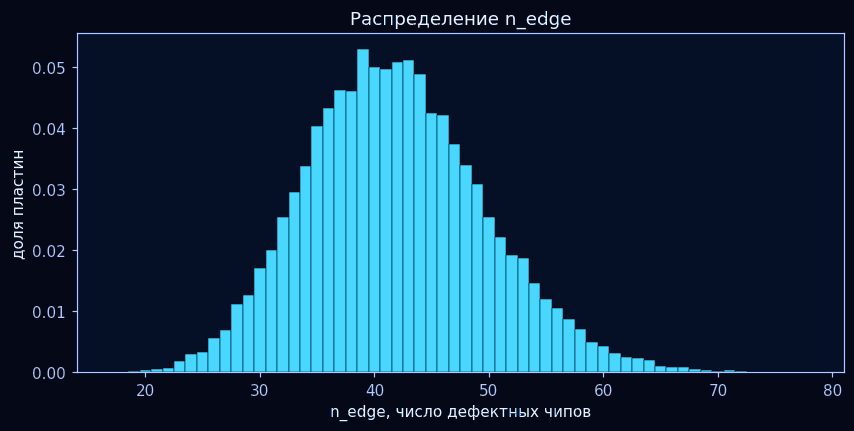

In [14]:
# @title Показать код
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(x, bins=np.arange(x.max() + 2) - 0.5, density=True,
        color=SPACE_COLORS["cyan"], edgecolor=SPACE_COLORS["soft"], linewidth=0.3)
ax.set_xlim(x.min() - 2, x.max() + 2)
ax.set_xlabel("n_edge, число дефектных чипов")
ax.set_ylabel("доля пластин")
ax.set_title("Распределение n_edge")
style_axis(ax)
plt.show()


#### 01.2.4. Описательные статистики


In [15]:
# @title Показать код
desc = pd.Series({
    "n": len(x),
    "среднее": x.mean(),
    "дисперсия (ddof=1)": x.var(ddof=1),
    "ст. отклонение": x.std(ddof=1),
    "медиана": x.median(),
    "q05": x.quantile(0.05),
    "q25": x.quantile(0.25),
    "q50": x.quantile(0.50),
    "q75": x.quantile(0.75),
    "q95": x.quantile(0.95),
    "min": x.min(),
    "max": x.max(),
    "асимметрия": stats.skew(x),
    "эксцесс (избыточный)": stats.kurtosis(x),
    "доля нулей": (x == 0).mean(),
    "индекс дисперсии D = var/mean": x.var(ddof=1) / x.mean(),
})
print("доля нулей n_center:", (df["n_center"] == 0).mean())
desc.round(4)

доля нулей n_center: 0.0


n                                15881.0000
среднее                             41.8697
дисперсия (ddof=1)                  60.8895
ст. отклонение                       7.8032
медиана                             41.0000
q05                                 30.0000
q25                                 36.0000
q50                                 41.0000
q75                                 47.0000
q95                                 55.0000
min                                 16.0000
max                                 79.0000
асимметрия                           0.3144
эксцесс (избыточный)                 0.1074
доля нулей                           0.0000
индекс дисперсии D = var/mean        1.4543
dtype: float64

По сводным данным в краевой зоне в среднем 41,87 дефектного чипа на пластину, стандартное отклонение — 7,80 чипа. Дальше сравниваем модели, чтобы оценить, какая из них лучше описывает форму распределения.


#### 01.2.5. Подгонка распределений


In [16]:
# @title Показать код
xv = x.to_numpy()
N = len(xv)
m, v = xv.mean(), xv.var(ddof=1)

# Пуассон: ММП lambda = среднее
lam_hat = m
ll_pois = stats.poisson.logpmf(xv, lam_hat).sum()

# ОБР: старт по методу моментов, затем ММП (exp для n, логит для p)
n_mm, p_mm = m**2 / (v - m), m / v

def nll_nb(t, data):
    n_, p_ = np.exp(t[0]), 1 / (1 + np.exp(-t[1]))
    return -stats.nbinom.logpmf(data, n_, p_).sum()

def fit_nbinom(data, start):
    res = optimize.minimize(nll_nb, start, args=(data,), method="Nelder-Mead",
                            options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 5000})
    return np.exp(res.x[0]), 1 / (1 + np.exp(-res.x[1])), res

start_nb = [np.log(n_mm), np.log(p_mm / (1 - p_mm))]
n_hat, p_hat, res_nb = fit_nbinom(xv, start_nb)
ll_nb = -res_nb.fun

# дискретизированное нормальное: P(k) = Phi(k+0.5) - Phi(k-0.5), ММП
def norm_pmf(k, mu, sd):
    return stats.norm.cdf(k + 0.5, mu, sd) - stats.norm.cdf(k - 0.5, mu, sd)

def fit_dnorm(data):
    res = optimize.minimize(lambda t: -np.log(norm_pmf(data, t[0], np.exp(t[1]))).sum(),
                            [data.mean(), np.log(data.std(ddof=1))], method="Nelder-Mead")
    return res.x[0], np.exp(res.x[1]), res

mu_hat, sd_hat, res_dn = fit_dnorm(xv)
ll_dn = -res_dn.fun

print("сходимость ОБР:", res_nb.success, "| дискр. нормальное:", res_dn.success)
print(f"метод моментов ОБР: n = {n_mm:.4f}, p = {p_mm:.6f}")
print(f"ММП ОБР:            n = {n_hat:.4f}, p = {p_hat:.6f}")
print(f"ОБР: среднее = {stats.nbinom.mean(n_hat, p_hat):.4f}, дисперсия = {stats.nbinom.var(n_hat, p_hat):.4f}")
print(f"Пуассон: lambda = {lam_hat:.4f}")
print(f"дискр. нормальное: mu = {mu_hat:.4f}, sigma = {sd_hat:.4f}")

сходимость ОБР: True | дискр. нормальное: True
метод моментов ОБР: n = 92.1710, p = 0.687634
ММП ОБР:            n = 93.0071, p = 0.689571
ОБР: среднее = 41.8697, дисперсия = 60.7185
Пуассон: lambda = 41.8697
дискр. нормальное: mu = 41.8697, sigma = 7.7976


In [17]:
# @title Показать код
models = {
    "Пуассон": {"k": 1, "ll": ll_pois, "params": f"lambda={lam_hat:.3f}",
                "pmf": lambda k: stats.poisson.pmf(k, lam_hat)},
    "ОБР": {"k": 2, "ll": ll_nb, "params": f"n={n_hat:.3f}, p={p_hat:.4f}",
            "pmf": lambda k: stats.nbinom.pmf(k, n_hat, p_hat)},
    "дискр. нормальное": {"k": 2, "ll": ll_dn, "params": f"mu={mu_hat:.3f}, sigma={sd_hat:.3f}",
                          "pmf": lambda k: norm_pmf(k, mu_hat, sd_hat)},
}
aic_table = pd.DataFrame({
    name: {"параметры": d["params"], "число параметров": d["k"],
           "logL": d["ll"], "AIC": 2 * d["k"] - 2 * d["ll"]}
    for name, d in models.items()
}).T
aic_table["dAIC"] = aic_table["AIC"].astype(float) - aic_table["AIC"].astype(float).min()
aic_table

,параметры,число параметров,logL,AIC,dAIC
Пуассон,lambda=41.870,1,-55660.854062,111323.708124,1250.440298
ОБР,"n=93.007, p=0.6896",2,-55034.633913,110073.267826,0.000000
дискр. нормальное,"mu=41.870, sigma=7.798",2,-55161.661385,110327.322769,254.054943


In [18]:
# @title Показать код
# LR-тест Пуассон против ОБР (граничная гипотеза: p-value из chi2(1) делим пополам)
lr = 2 * (ll_nb - ll_pois)
p_lr = 0.5 * stats.chi2.sf(lr, df=1)
print(f"LR = {lr:.4f}, p-value = {p_lr:.3e}")

LR = 1252.4403, p-value = 1.224e-274


In [19]:
# @title Показать код
# доля нулей: наблюдаемая и по моделям
pd.Series({
    "наблюдаемая": (xv == 0).mean(),
    "Пуассон exp(-lambda)": np.exp(-lam_hat),
    "ОБР p^n": p_hat**n_hat,
    "дискр. нормальное": norm_pmf(0, mu_hat, sd_hat),
})

наблюдаемая             0.000000e+00
Пуассон exp(-lambda)    6.549562e-19
ОБР p^n                 9.697971e-16
дискр. нормальное       2.859985e-08
dtype: float64

#### 01.2.6. Сравнение моделей с данными


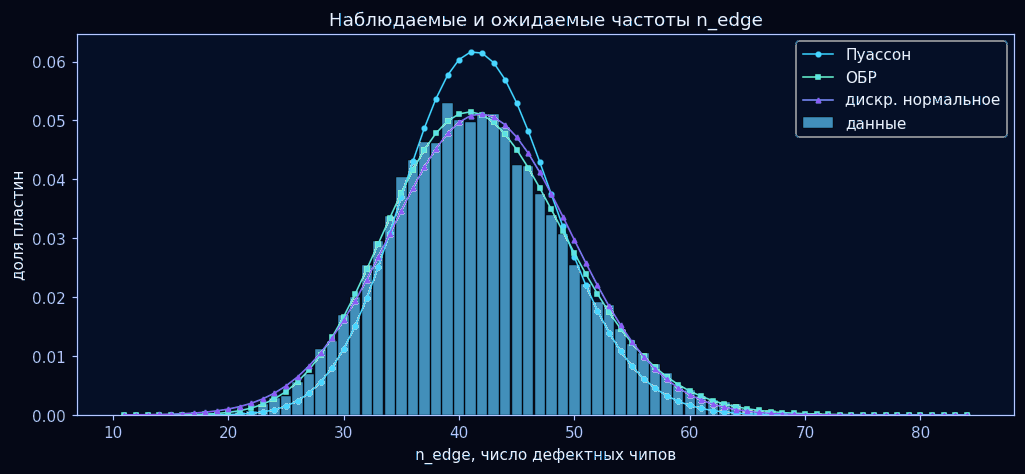

In [20]:
# @title Показать код
ks = np.arange(xv.min() - 5, xv.max() + 6)
obs_freq = np.array([(xv == k).sum() for k in ks]) / N

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(ks, obs_freq, width=0.9, color=SPACE_COLORS["cyan"], edgecolor=SPACE_COLORS["soft"], linewidth=0.3, alpha=0.45, label="данные")
for (name, d), mk in zip(models.items(), ["o", "s", "^"]):
    ax.plot(ks, d["pmf"](ks), mk + "-", ms=4, lw=1.6, label=name)
ax.set_xlabel("n_edge, число дефектных чипов")
ax.set_ylabel("доля пластин")
ax.set_title("Наблюдаемые и ожидаемые частоты n_edge")
ax.legend()
style_axis(ax)
plt.show()


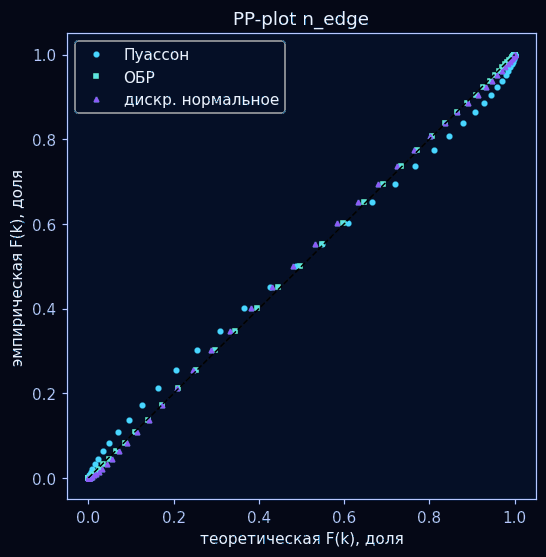

In [21]:
# @title Показать код
# PP-plot ступенчатых CDF в точках k
emp_cdf = np.array([(xv <= k).mean() for k in ks])
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for (name, d), mk in zip(models.items(), ["o", "s", "^"]):
    ax.plot(np.cumsum(d["pmf"](np.arange(0, ks.max() + 1)))[ks], emp_cdf, mk, ms=4, label=name)
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1.6, color=SPACE_COLORS["magenta"], label="идеал")
ax.set_xlabel("теоретическая F(k), доля")
ax.set_ylabel("эмпирическая F(k), доля")
ax.set_title("PP-plot n_edge")
ax.legend()
style_axis(ax)
plt.show()


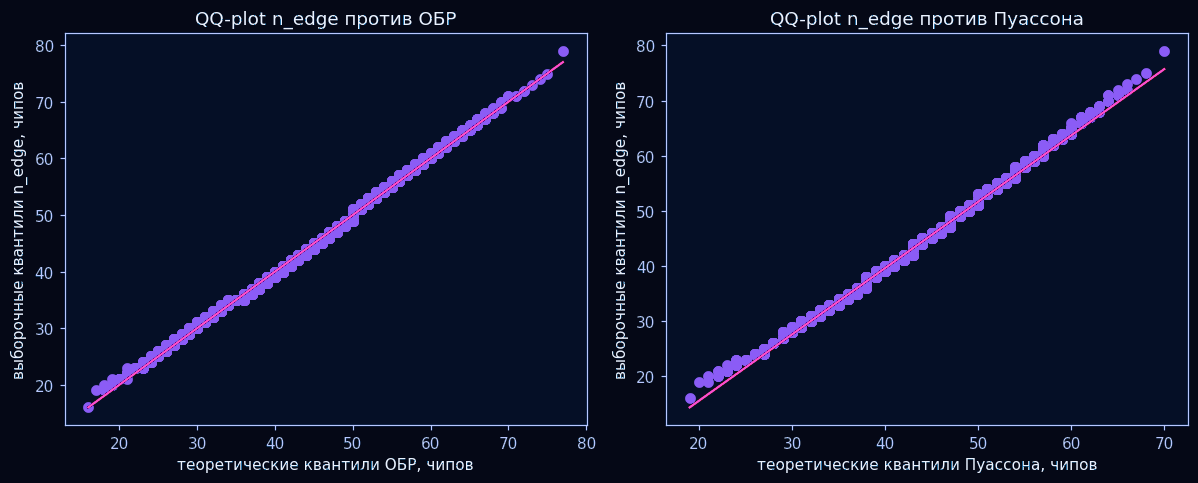

In [22]:
# @title Показать код
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
stats.probplot(xv, dist=stats.nbinom, sparams=(n_hat, p_hat), plot=axes[0])
style_probplot(axes[0])
axes[0].set_title("QQ-plot n_edge против ОБР")
axes[0].set_xlabel("теоретические квантили ОБР, чипов")
axes[0].set_ylabel("выборочные квантили n_edge, чипов")
stats.probplot(xv, dist=stats.poisson, sparams=(lam_hat,), plot=axes[1])
style_probplot(axes[1])
axes[1].set_title("QQ-plot n_edge против Пуассона")
axes[1].set_xlabel("теоретические квантили Пуассона, чипов")
axes[1].set_ylabel("выборочные квантили n_edge, чипов")
plt.tight_layout()
plt.show()


#### 01.2.7. Нормализация


In [23]:
# @title Показать код
x_bc, lam_bc = stats.boxcox(xv + 1)
print(f"Бокс-Кокс на x+1: lambda = {lam_bc:.4f}")

transforms = {
    "исходные": xv.astype(float),
    "z-score": (xv - xv.mean()) / xv.std(ddof=1),
    "log1p": np.log1p(xv),
    "Бокс-Кокс(x+1)": x_bc,
    "Анскомб 2*sqrt(x+3/8)": 2 * np.sqrt(xv + 3 / 8),
}
pd.DataFrame({name: {"асимметрия": stats.skew(t), "эксцесс (избыточный)": stats.kurtosis(t)}
              for name, t in transforms.items()}).T.round(4)

Бокс-Кокс на x+1: lambda = 0.4152


,асимметрия,эксцесс (избыточный)
исходные,0.3144,0.1074
z-score,0.3144,0.1074
log1p,-0.2303,0.0906
Бокс-Кокс(x+1),-0.0007,-0.0278
Анскомб 2*sqrt(x+3/8),0.0412,-0.0285


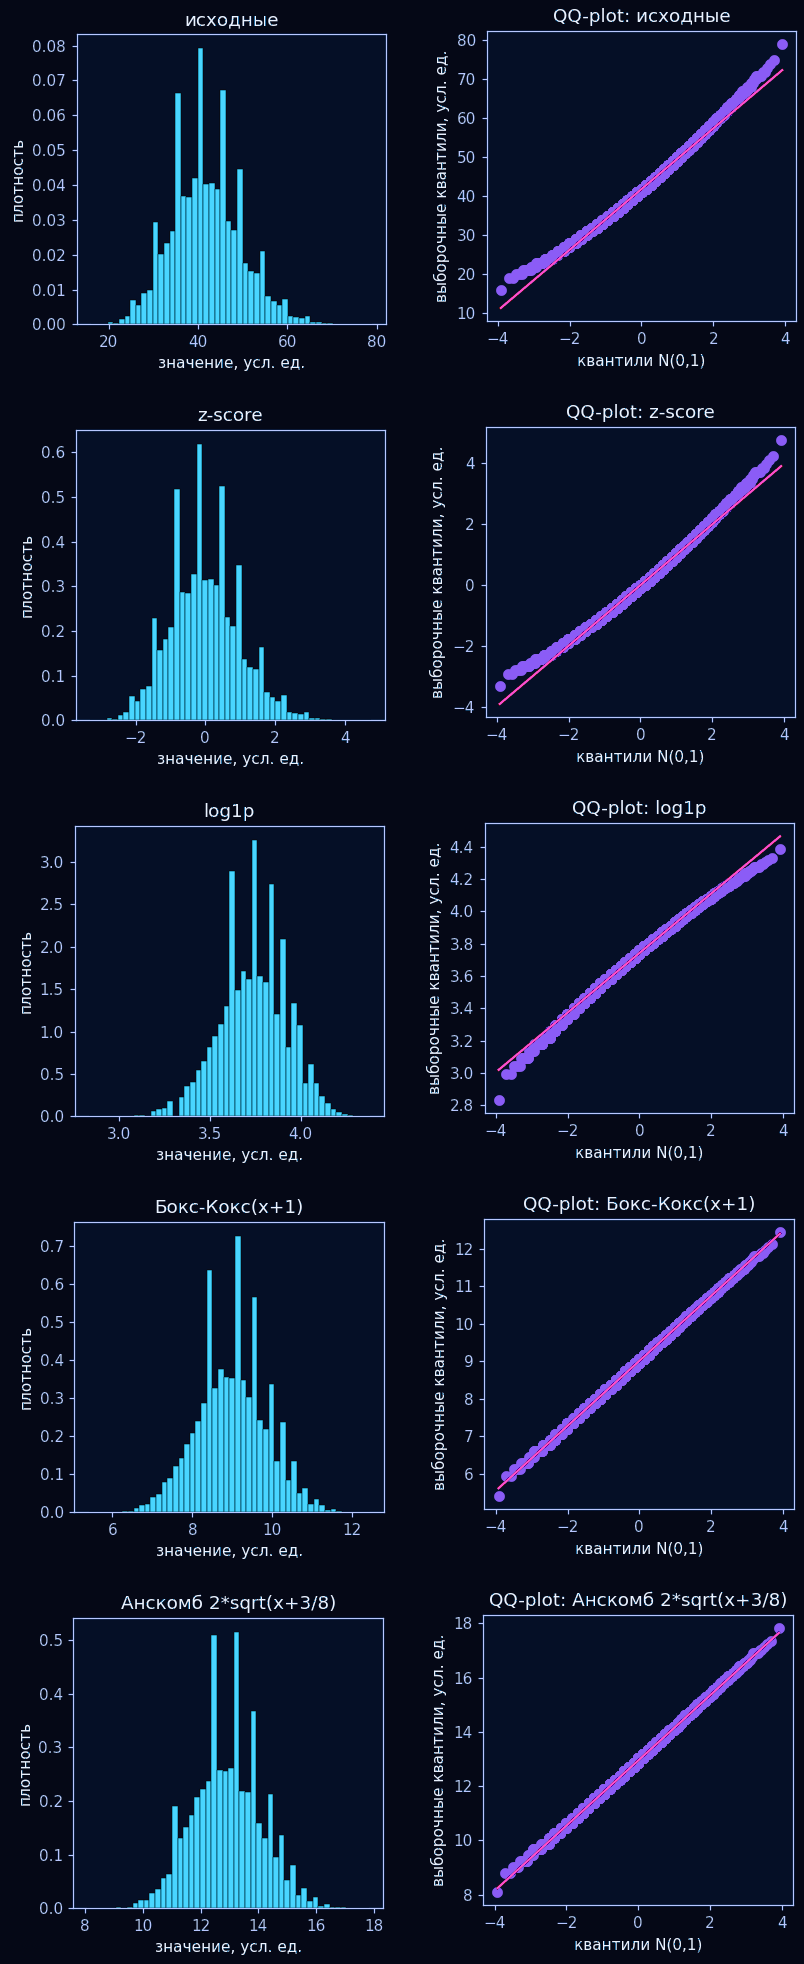

In [24]:
# @title Показать код
fig, axes = plt.subplots(len(transforms), 2, figsize=(12.6, 3.9 * len(transforms)))
hist_colors = [SPACE_COLORS["cyan"], SPACE_COLORS["teal"], SPACE_COLORS["violet"], SPACE_COLORS["magenta"], SPACE_COLORS["gold"]]
qq_colors = [SPACE_COLORS["violet"], SPACE_COLORS["magenta"], SPACE_COLORS["cyan"], SPACE_COLORS["gold"], SPACE_COLORS["mint"]]
for j, (name, t) in enumerate(transforms.items()):
    hax, qax = axes[j, 0], axes[j, 1]
    hax.hist(t, bins=50, density=True, color=hist_colors[j % len(hist_colors)], edgecolor=SPACE_COLORS["soft"], linewidth=0.35)
    hax.set_title(name)
    hax.set_xlabel("Число дефектных чипов" if name == "исходные" else "преобразованная шкала (безразмерная)")
    hax.set_ylabel("плотность")
    style_axis(hax)
    stats.probplot(t, dist="norm", plot=qax)
    style_probplot(qax, point_color=qq_colors[j % len(qq_colors)], line_color=SPACE_COLORS["magenta"])
    qax.set_title(f"QQ-plot: {name}")
    qax.set_xlabel("квантили N(0,1)")
    qax.set_ylabel("выборочные квантили, число дефектных чипов" if name == "исходные" else "выборочные квантили (безразмерные)")
plt.tight_layout()
plt.show()


После преобразования шкала меняется. Поэтому по этим графикам сравниваем форму распределений, а число чипов читаем по графику в исходной шкале.


#### 01.2.8. Формулы распределений

Для Пуассона $P(X=k)=e^{-\lambda}\lambda^k/k!$ и $E(X)=\operatorname{Var}(X)=\lambda$. Отрицательное биномиальное распределение допускает дисперсию выше среднего. Третья модель округляет нормальную величину: $P(X=k)=\Phi((k+0.5-\mu)/\sigma)-\Phi((k-0.5-\mu)/\sigma)$.


#### 01.2.9. Проверка оценок на выборках


In [25]:
# @title Показать код
# выборки с возвращением из всей совокупности, N_REP повторов на каждый размер
sizes = np.unique(np.logspace(1, np.log10(N), 15).astype(int))
true_vals = {"среднее": xv.mean(), "дисперсия": xv.var(ddof=1), "медиана": np.median(xv)}

rows = []
for n in sizes:
    est = np.array([[s.mean(), s.var(ddof=1), np.median(s)]
                    for s in (rng.choice(xv, n, replace=True) for _ in range(N_REP))])
    for j, name in enumerate(true_vals):
        q05, q50, q95 = np.quantile(est[:, j], [0.05, 0.5, 0.95])
        rows.append({"n": n, "оценка": name, "q05": q05, "медиана": q50, "q95": q95})
cons = pd.DataFrame(rows)
cons["ширина 5-95%"] = cons["q95"] - cons["q05"]
cons.pivot(index="n", columns="оценка", values="ширина 5-95%").round(3)

оценка,дисперсия,медиана,среднее
n,,,
10,80.525,10.050,7.630
16,70.078,8.500,6.566
28,55.469,6.025,4.895
48,42.583,4.550,4.223
82,29.627,3.500,3.204
139,23.498,3.000,2.262
235,16.760,3.000,1.709
398,13.925,1.000,1.276
674,10.225,1.000,0.983


#### 01.2.10. Состоятельность оценок


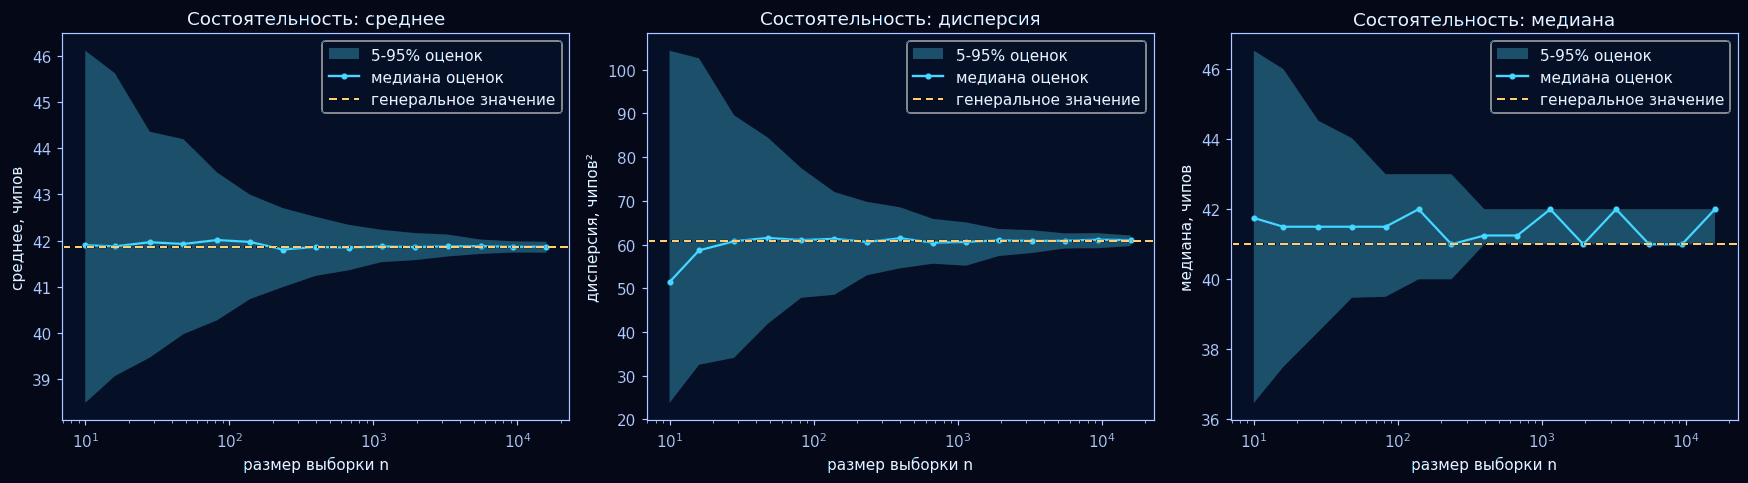

In [26]:
# @title Показать код
units = {"среднее": "чипов", "дисперсия": "чипов²", "медиана": "чипов"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, true_vals):
    c = cons[cons["оценка"] == name]
    ax.fill_between(c["n"], c["q05"], c["q95"], alpha=0.3, label="5-95% оценок")
    ax.semilogx(c["n"], c["медиана"], "o-", ms=3, label="медиана оценок")
    ax.axhline(true_vals[name], color=SPACE_COLORS["gold"], ls="--", lw=1.5, label="генеральное значение")
    ax.set_xlabel("размер выборки n")
    ax.set_ylabel(f"{name}, {units[name]}")
    ax.set_title(f"Состоятельность: {name}")
    ax.legend()
plt.tight_layout()
plt.show()

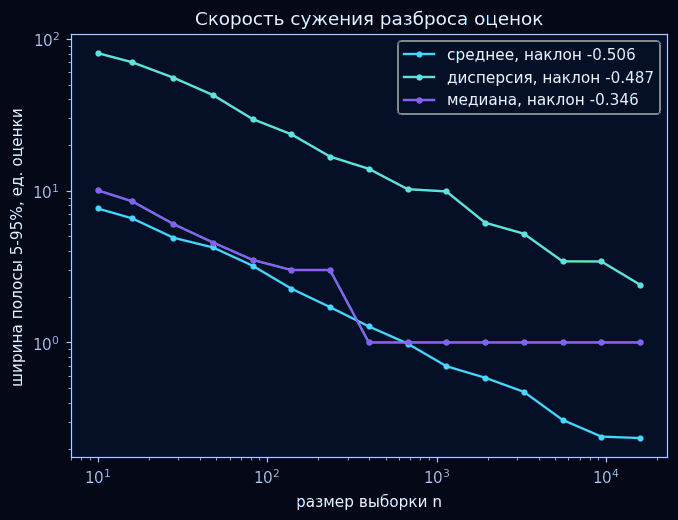

среднее     -0.5058
дисперсия   -0.4869
медиана     -0.3456
Name: наклон, dtype: float64

In [27]:
# @title Показать код
# ширина полосы 5-95% против n в log-log, наклон по np.polyfit
fig, ax = plt.subplots(figsize=(7, 5))
slopes = {}
for name in true_vals:
    c = cons[(cons["оценка"] == name) & (cons["ширина 5-95%"] > 0)]
    slopes[name] = np.polyfit(np.log10(c["n"]), np.log10(c["ширина 5-95%"]), 1)[0]
    ax.loglog(c["n"], c["ширина 5-95%"], "o-", ms=3, label=f"{name}, наклон {slopes[name]:.3f}")
ax.set_xlabel("размер выборки n")
ax.set_ylabel("ширина полосы 5-95%, ед. оценки")
ax.set_title("Скорость сужения разброса оценок")
ax.legend()
plt.show()
pd.Series(slopes, name="наклон").round(4)

#### 01.2.11. Выборки с возвращением и без


In [28]:
# @title Показать код
s_with = x.sample(N_SAMPLE, replace=True, random_state=SEED)
s_without = x.sample(N_SAMPLE, replace=False, random_state=SEED)

def summary(s):
    return pd.Series({"n": len(s), "среднее": s.mean(), "дисперсия": s.var(ddof=1),
                      "q05": s.quantile(0.05), "q25": s.quantile(0.25), "медиана": s.median(),
                      "q75": s.quantile(0.75), "q95": s.quantile(0.95)})

pd.DataFrame({"генеральная": summary(x), "с возвращением": summary(s_with),
              "без возвращения": summary(s_without)}).round(3)

,генеральная,с возвращением,без возвращения
n,15881.00,1000.000,1000.000
среднее,41.87,42.244,41.986
дисперсия,60.89,63.490,56.680
q05,30.00,30.000,30.000
q25,36.00,37.000,37.000
медиана,41.00,42.000,42.000
q75,47.00,47.000,47.000
q95,55.00,56.000,56.000


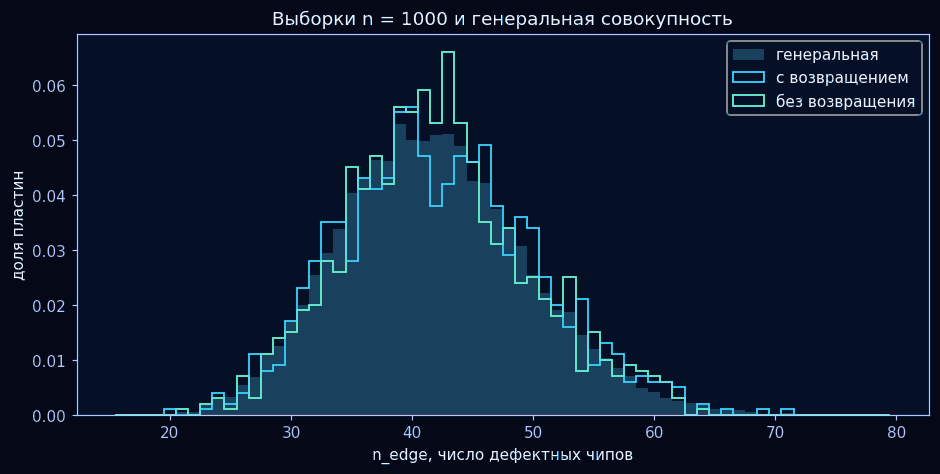

In [29]:
# @title Показать код
bins = np.arange(x.min(), x.max() + 2) - 0.5
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(x, bins=bins, density=True, histtype="stepfilled", alpha=0.22, color=SPACE_COLORS["cyan"], label="генеральная")
ax.hist(s_with, bins=bins, density=True, histtype="step", lw=1.5, color=SPACE_COLORS["violet"], label="с возвращением")
ax.hist(s_without, bins=bins, density=True, histtype="step", lw=1.5, color=SPACE_COLORS["magenta"], label="без возвращения")
ax.set_xlabel("n_edge, число дефектных чипов")
ax.set_ylabel("доля пластин")
ax.set_title(f"Выборки n = {N_SAMPLE} и генеральная совокупность")
ax.legend()
style_axis(ax)
plt.show()


**Сравнение распределений полного набора и выборок.** В полном наборе у края в среднем 41,87 дефекта. В двух выборках по 1000 пластин получилось 42,24 и 41,99. Средние близки, хотя разброс отдельных значений различается. Чтобы понять, типично ли это, дальше повторяем отбор много раз.


In [30]:
# @title Показать код
# группы по децилям генеральной совокупности (группы 0/1/2/3+ не подходят: min(n_edge) > 0)
edges = np.unique(np.quantile(x, np.linspace(0, 1, 11)))
edges[0], edges[-1] = -np.inf, np.inf
grp = lambda s: pd.cut(s, edges)

# без возвращения: выборка против дополнения, chi2 однородности
complement = x.drop(s_without.index)
tab = pd.crosstab(np.r_[np.zeros(len(s_without)), np.ones(len(complement))],
                  np.r_[grp(s_without).astype(str), grp(complement).astype(str)])
chi2_h, p_h, dof_h, E_h = stats.chi2_contingency(tab)
print(f"без возвращения vs дополнение: chi2 = {chi2_h:.3f}, df = {dof_h}, p = {p_h:.4f}, min E = {E_h.min():.1f}")

# с возвращением: chi2 согласия с долями генеральной совокупности
p_pop = grp(x).value_counts(normalize=True).sort_index()
o_w = grp(s_with).value_counts().sort_index()
chi2_w, p_w = stats.chisquare(o_w.values, p_pop.values * len(s_with))
print(f"с возвращением vs генеральная: chi2 = {chi2_w:.3f}, df = {len(o_w) - 1}, p = {p_w:.4f}")

for name, s, ref in [("с возвращением vs генеральная", s_with, x),
                     ("без возвращения vs дополнение", s_without, complement)]:
    r = stats.ks_2samp(s, ref)
    print(f"KS {name}: D = {r.statistic:.4f}, p = {r.pvalue:.4f}")

без возвращения vs дополнение: chi2 = 8.737, df = 9, p = 0.4619, min E = 71.5
с возвращением vs генеральная: chi2 = 10.599, df = 9, p = 0.3042
KS с возвращением vs генеральная: D = 0.0336, p = 0.2334
KS без возвращения vs дополнение: D = 0.0243, p = 0.6283


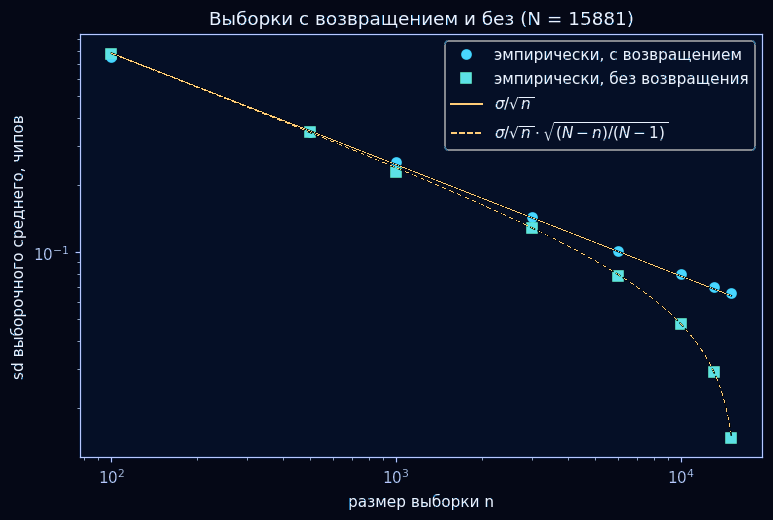

,n,n/N,sd с возвр.,sd без возвр.,теория sigma/sqrt(n),теория с FPC
0,100,0.0063,0.7505,0.7709,0.7803,0.7779
1,500,0.0315,0.3447,0.3443,0.3490,0.3434
2,1000,0.0630,0.2535,0.2294,0.2468,0.2389
3,3000,0.1889,0.1438,0.1288,0.1425,0.1283
4,6000,0.3778,0.1009,0.0785,0.1007,0.0795
5,10000,0.6297,0.0799,0.0476,0.0780,0.0475
6,13000,0.8186,0.0699,0.0291,0.0684,0.0291
7,15000,0.9445,0.0654,0.0147,0.0637,0.0150


In [31]:
# @title Показать код
# Монте-Карло: sd выборочного среднего с возвращением и без против теории
sigma = xv.std(ddof=0)
n_grid = np.array([100, 500, 1000, 3000, 6000, 10000, 13000, 15000])
mc = []
for n in n_grid:
    m_with = [rng.choice(xv, n, replace=True).mean() for _ in range(N_MC)]
    m_without = [rng.choice(xv, n, replace=False).mean() for _ in range(N_MC)]
    mc.append({"n": n, "n/N": n / N, "sd с возвр.": np.std(m_with, ddof=1),
               "sd без возвр.": np.std(m_without, ddof=1),
               "теория sigma/sqrt(n)": sigma / np.sqrt(n),
               "теория с FPC": sigma / np.sqrt(n) * np.sqrt((N - n) / (N - 1))})
mc = pd.DataFrame(mc)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(mc["n"], mc["sd с возвр."], "o", label="эмпирически, с возвращением")
ax.loglog(mc["n"], mc["sd без возвр."], "s", label="эмпирически, без возвращения")
nn = np.linspace(n_grid.min(), n_grid.max(), 400)
ax.loglog(nn, sigma / np.sqrt(nn), "-", lw=1.6, color=SPACE_COLORS["gold"], label=r"$\sigma/\sqrt{n}$")
ax.loglog(nn, sigma / np.sqrt(nn) * np.sqrt((N - nn) / (N - 1)), "--", lw=1.6, color=SPACE_COLORS["gold"],
          label=r"$\sigma/\sqrt{n}\cdot\sqrt{(N-n)/(N-1)}$")
ax.set_xlabel("размер выборки n")
ax.set_ylabel("sd выборочного среднего, чипов")
ax.set_title(f"Выборки с возвращением и без (N = {N})")
ax.legend()
plt.show()
mc.round(4)

**Различия между способами отбора.** При малой выборке кривые близки. Когда берём почти весь набор, без возвращения одни и те же пластины не повторяются, поэтому среднее меняется от выборки к выборке гораздо меньше. Например, для 15 000 пластин теоретический разброс среднего — около 0,015 чипа без возвращения и 0,064 с возвращением.


#### 01.2.12. Проверка гипотез


In [32]:
# @title Показать код
# лучшая модель по AIC; chi2 согласия с объединением хвостов (все E >= 5)
best = aic_table["AIC"].astype(float).idxmin()
print("модель для chi2:", best)

def bin_expected(pmf, n_obs, kmax):
    """Ожидаемые по k=0..kmax (последний бин: >= kmax), объединение соседних до E >= 5."""
    k = np.arange(kmax + 1)
    p = pmf(k[:-1])
    probs = np.append(p, 1 - p.sum())
    E = n_obs * probs
    groups, cur, acc = [], [], 0.0
    for i, e in enumerate(E):
        cur.append(i)
        acc += e
        if acc >= 5:
            groups.append(cur)
            cur, acc = [], 0.0
    if cur:
        groups[-1] += cur
    return groups, np.array([E[g].sum() for g in groups])

def chi2_gof(data, pmf, n_params):
    kmax = int(data.max()) + 1
    groups, E = bin_expected(pmf, len(data), kmax)
    counts = np.bincount(np.minimum(data, kmax), minlength=kmax + 1)
    O = np.array([counts[g].sum() for g in groups])
    stat, p = stats.chisquare(O, E, ddof=n_params)
    return stat, p, len(groups) - 1 - n_params, groups, O, E

chi2_obs, p_chi2, df_chi2, groups, O, E = chi2_gof(xv, models[best]["pmf"], models[best]["k"])
labels = [f"<={g[-1]}" if i == 0 else (f">={g[0]}" if i == len(groups) - 1 else
          (str(g[0]) if len(g) == 1 else f"{g[0]}-{g[-1]}")) for i, g in enumerate(groups)]
print(f"chi2 = {chi2_obs:.3f}, df = {df_chi2}, p = {p_chi2:.3e}, бинов = {len(groups)}")
pd.DataFrame({"бин": labels, "O": O, "E": E.round(2), "(O-E)^2/E": ((O - E) ** 2 / E).round(3)})

модель для chi2: ОБР
chi2 = 46.377, df = 49, p = 5.801e-01, бинов = 52


,бин,O,E,(O-E)^2/E
0,<=19,3,8.44,3.505
1,20,4,6.95,1.252
2,21,9,11.61,0.587
3,22,10,18.68,4.031
4,23,29,28.99,0.000
5,24,46,43.50,0.144
6,25,51,63.20,2.356
7,26,88,89.05,0.012
8,27,110,121.84,1.151
9,28,178,162.11,1.557


бутстрап: B = 300, p = 0.5581, медиана chi2* = 48.47


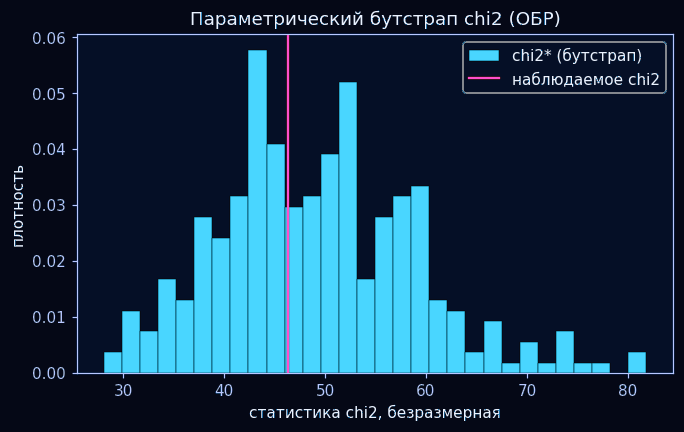

In [33]:
# @title Показать код
# параметрический бутстрап p-value для chi2: генерация из подогнанной модели, переоценка, chi2
def refit(data):
    if best == "Пуассон":
        lam = data.mean()
        return lambda k: stats.poisson.pmf(k, lam)
    if best == "ОБР":
        n_, p_, _ = fit_nbinom(data, [np.log(n_hat), np.log(p_hat / (1 - p_hat))])
        return lambda k: stats.nbinom.pmf(k, n_, p_)
    mu_, sd_, _ = fit_dnorm(data)
    return lambda k: norm_pmf(k, mu_, sd_)

def simulate(n):
    if best == "Пуассон":
        return rng.poisson(lam_hat, n)
    if best == "ОБР":
        return stats.nbinom.rvs(n_hat, p_hat, size=n, random_state=rng)
    return np.clip(np.round(rng.normal(mu_hat, sd_hat, n)), 0, None).astype(int)

chi2_boot = np.empty(B_BOOT)
for b in range(B_BOOT):
    xb = simulate(N)
    chi2_boot[b] = chi2_gof(xb, refit(xb), models[best]["k"])[0]
p_boot = (1 + np.sum(chi2_boot >= chi2_obs)) / (B_BOOT + 1)
print(f"бутстрап: B = {B_BOOT}, p = {p_boot:.4f}, медиана chi2* = {np.median(chi2_boot):.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(chi2_boot, bins=30, density=True, color=SPACE_COLORS["violet"], edgecolor=SPACE_COLORS["soft"], linewidth=0.3, alpha=0.8, label="chi2* (бутстрап)")
ax.axvline(chi2_obs, color=SPACE_COLORS["gold"], linewidth=1.8, label="наблюдаемое chi2")
ax.set_xlabel("статистика chi2, безразмерная")
ax.set_ylabel("плотность вероятности")
ax.legend()
style_axis(ax)
plt.show()


In [34]:
# @title Показать код
# Манн-Уитни: Training против Test
tr = df.loc[df["trianTestLabel"] == "Training", "n_edge"]
te = df.loc[df["trianTestLabel"] == "Test", "n_edge"]
mw = stats.mannwhitneyu(tr, te, alternative="two-sided", method="asymptotic")
mw_effect = mw.statistic / (len(tr) * len(te))
pd.Series({"n Training": len(tr), "n Test": len(te),
           "среднее Training": tr.mean(), "среднее Test": te.mean(),
           "медиана Training": tr.median(), "медиана Test": te.median(),
           "U": mw.statistic, "p-value": mw.pvalue, "U/(n1*n2)": mw_effect})

n Training          1.300500e+04
n Test              2.876000e+03
среднее Training    4.224237e+01
среднее Test        4.018463e+01
медиана Training    4.200000e+01
медиана Test        4.000000e+01
U                   2.151291e+07
p-value             1.158789e-36
U/(n1*n2)           5.751749e-01
dtype: float64

In [35]:
# @title Показать код
# центр против края по плотностям дефектов
# допущение: числа чипов в зонах в данных нет, чипов в зоне ~ доля площади диска * n_die
frac_c = R_CENTER**2               # r < 0.5
frac_e = 1 - R_EDGE**2             # r > 0.8
rho_c = df["n_center"] / (frac_c * df["n_die"])
rho_e = df["n_edge"] / (frac_e * df["n_die"])
diff = rho_e - rho_c

wx = stats.wilcoxon(diff, alternative="two-sided")
sum_c, sum_e = int(df["n_center"].sum()), int(df["n_edge"].sum())
bt = stats.binomtest(sum_e, sum_e + sum_c, p=frac_e / (frac_e + frac_c))

pd.Series({"доля площади центра": frac_c, "доля площади края": frac_e,
           "средняя плотность центр": rho_c.mean(), "средняя плотность край": rho_e.mean(),
           "медиана разности (край - центр)": diff.median(),
           "доля пластин, где край > центра": (diff > 0).mean(),
           "Wilcoxon W": wx.statistic, "Wilcoxon p": wx.pvalue,
           "binomtest: доля краевых среди (край+центр)": sum_e / (sum_e + sum_c),
           "binomtest: ожидаемая доля": frac_e / (frac_e + frac_c),
           "binomtest p": bt.pvalue})

доля площади центра                           2.500000e-01
доля площади края                             3.600000e-01
средняя плотность центр                       1.780217e-01
средняя плотность край                        2.253968e-01
медиана разности (край - центр)               4.715762e-02
доля пластин, где край > центра               8.180215e-01
Wilcoxon W                                    1.321294e+07
Wilcoxon p                                    0.000000e+00
binomtest: доля краевых среди (край+центр)    6.457936e-01
binomtest: ожидаемая доля                     5.901639e-01
binomtest p                                   0.000000e+00
dtype: float64

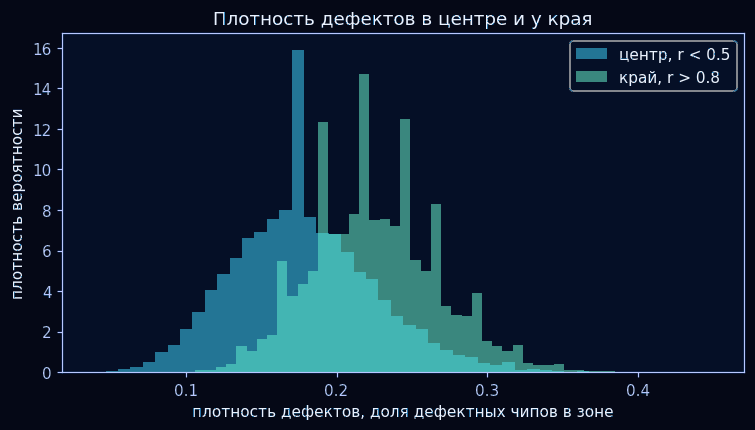

In [36]:
# @title Показать код
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(rho_c, bins=50, density=True, alpha=0.48, color=SPACE_COLORS["cyan"], label="центр, r < 0.5")
ax.hist(rho_e, bins=50, density=True, alpha=0.45, color=SPACE_COLORS["violet"], label="край, r > 0.8")
ax.set_xlabel("плотность дефектов, доля дефектных чипов в зоне")
ax.set_ylabel("плотность вероятности")
ax.set_title("Плотность дефектов в центре и у края")
ax.legend()
style_axis(ax)
plt.show()


#### 01.2.13. Сводная таблица


In [37]:
# @title Показать код
summary_tab = pd.Series({
    "пластин (n)": N,
    "лотов": df["lotName"].nunique(),
    "dieSize": df["dieSize"].iloc[0],
    "среднее n_edge": m,
    "дисперсия n_edge": v,
    "индекс дисперсии D": v / m,
    "доля нулей": (xv == 0).mean(),
    "асимметрия": stats.skew(xv),
    "эксцесс": stats.kurtosis(xv),
    "внутрилотовая дисперсия": var_within,
    "межлотовая дисперсия": var_between,
    "ICC": icc,
    "Пуассон lambda": lam_hat,
    "ОБР n": n_hat,
    "ОБР p": p_hat,
    "дискр. нормальное mu": mu_hat,
    "дискр. нормальное sigma": sd_hat,
    "AIC Пуассон": aic_table.loc["Пуассон", "AIC"],
    "AIC ОБР": aic_table.loc["ОБР", "AIC"],
    "AIC дискр. нормальное": aic_table.loc["дискр. нормальное", "AIC"],
    "LR Пуассон vs ОБР": lr,
    "p LR": p_lr,
    "Бокс-Кокс lambda": lam_bc,
    f"chi2 согласия ({best})": chi2_obs,
    "df chi2": df_chi2,
    "p chi2": p_chi2,
    "p chi2 бутстрап": p_boot,
    "Манн-Уитни p": mw.pvalue,
    "Манн-Уитни U/(n1*n2)": mw_effect,
    "Wilcoxon p (край vs центр)": wx.pvalue,
    "binomtest p (край vs центр)": bt.pvalue,
}, dtype=object)
summary_tab.map(lambda v: f"{v:.6g}" if isinstance(v, (float, np.floating)) else v).to_frame("значение")

,значение
пластин (n),15881
лотов,715
dieSize,516
среднее n_edge,41.8697
дисперсия n_edge,60.8895
индекс дисперсии D,1.45426
доля нулей,0
асимметрия,0.31441
эксцесс,0.107374
внутрилотовая дисперсия,53.4556


#### 01.2.14. Выводы

У края в среднем 41,87 дефектного чипа на пластину, дисперсия — 60,89 чипа². По графикам повторных выборок разброс среднего уменьшается с ростом размера выборки. На одних и тех же размерах сравнение с возвращением и без показывает, как способ отбора меняет разброс.

Среди трёх моделей наименьший AIC у отрицательной биномиальной. Для неё критерий согласия χ² дал p ≈ 0,580. На уровне 5% гипотеза согласия не отвергается.


**Сравним центр и край.** Для отрицательной биномиальной модели на краю получили $p\approx0{,}580$, а в центре — $p\approx0{,}012$. При пороге 5% для края оснований отвергнуть согласие нет, а для центра есть. Поэтому дальше описываем зоны отдельно.


<a id="appstat-dependence"></a>

### 01.3. Связь числа дефектов в центре и у края


           n_center        n_edge
count  15881.000000  15881.000000
mean      22.964801     41.869719
std        6.116518      7.803173
min        5.000000     16.000000
25%       19.000000     36.000000
50%       23.000000     41.000000
75%       27.000000     47.000000
max       58.000000     79.000000


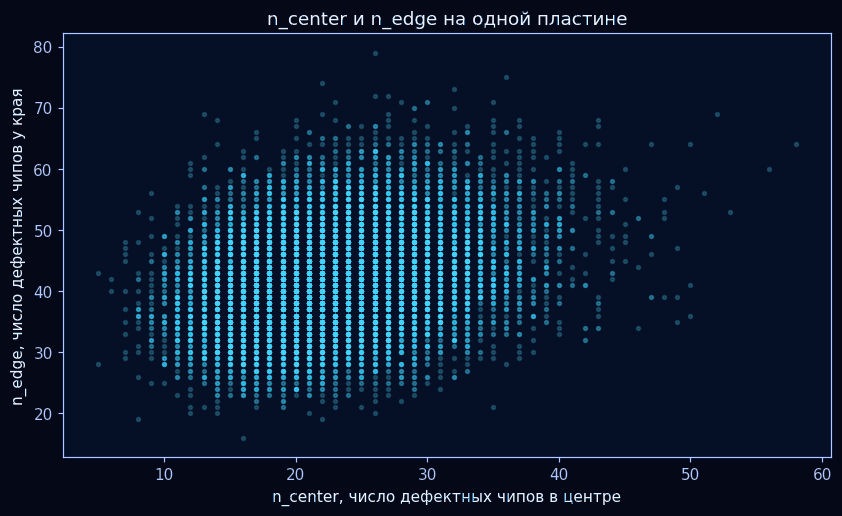

In [38]:
# @title Показать код
c, e = df["n_center"], df["n_edge"]
N = len(df)
print(df[["n_center", "n_edge"]].describe())

fig, ax = plt.subplots(figsize=(8.8, 5.2))
ax.scatter(c, e, s=8, alpha=0.22, color=SPACE_COLORS["cyan"], edgecolors="none")
ax.set_xlabel("n_center, число дефектных чипов в центре")
ax.set_ylabel("n_edge, число дефектных чипов у края")
ax.set_title("n_center и n_edge на одной пластине")
style_axis(ax)
plt.show()


На диаграмме обе оси показывают число дефектных чипов на одной пластине. В среднем значения растут вместе, но облако точек широкое. Проверим наблюдение статистически.


In [39]:
# @title Показать код
pr, pr_p = stats.pearsonr(c, e)
sp, sp_p = stats.spearmanr(c, e)
print(f"Пирсон = {pr:.3f} (p = {pr_p:.3g}) | Спирмен = {sp:.3f} (p = {sp_p:.3g})")

Пирсон = 0.279 (p = 1.35e-282) | Спирмен = 0.266 (p = 2.13e-254)


In [40]:
# @title Показать код
cb = pd.qcut(c, 5, duplicates="drop")
eb = pd.qcut(e, 5, duplicates="drop")
tab = pd.crosstab(cb, eb)
chi2, p, dof, exp = stats.chi2_contingency(tab)
V = np.sqrt(chi2 / (N * (min(tab.shape) - 1)))
print(tab)
print(f"chi2 = {chi2:.1f}, dof = {dof}, p = {p:.3g}, V Крамера = {V:.3f}, min ожид. = {exp.min():.1f}")

n_edge         (15.999, 35.0]  (35.0, 39.0]  ...  (43.0, 48.0]  (48.0, 79.0]
n_center                                     ...                            
(4.999, 18.0]            1243           783  ...           642           431
(18.0, 21.0]              730           659  ...           522           416
(21.0, 24.0]              610           613  ...           645           555
(24.0, 28.0]              498           548  ...           801           705
(28.0, 58.0]              287           393  ...           647           946

[5 rows x 5 columns]
chi2 = 1091.2, dof = 16, p = 3.23e-222, V Крамера = 0.131, min ожид. = 528.4


наблюдаемая = 0.266, p (перестановки) = 0.0002


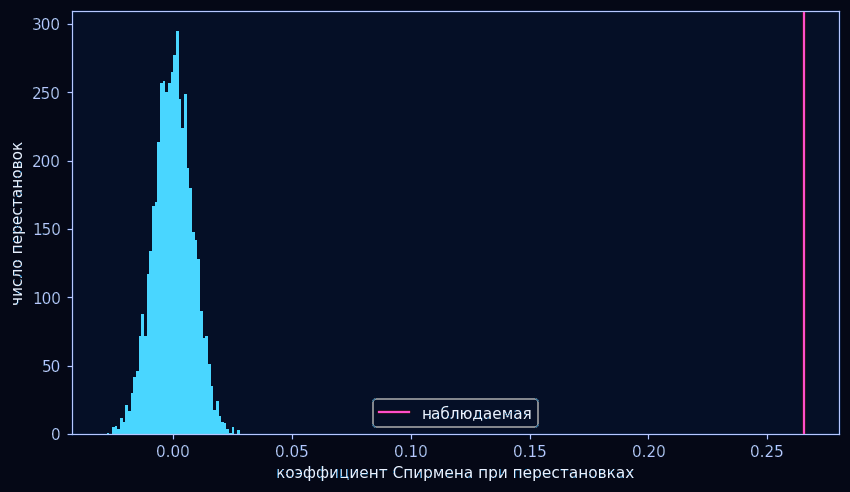

In [41]:
# @title Показать код
rng = np.random.default_rng(0)
rc, re_ = stats.rankdata(c), stats.rankdata(e)
obs = np.corrcoef(rc, re_)[0, 1]
perm = np.array([np.corrcoef(rc, rng.permutation(re_))[0, 1] for _ in range(5000)])
p_perm = (np.sum(np.abs(perm) >= abs(obs)) + 1) / (len(perm) + 1)
print(f"наблюдаемая = {obs:.3f}, p (перестановки) = {p_perm:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(perm, bins=50, color=SPACE_COLORS["violet"], edgecolor=SPACE_COLORS["soft"], alpha=0.82)
ax.axvline(obs, color=SPACE_COLORS["gold"], linewidth=1.8, label="наблюдаемая")
ax.set_xlabel("коэффициент Спирмена при перестановках")
ax.set_ylabel("число перестановок")
ax.legend()
style_axis(ax)
plt.show()


**Что проверили перестановками.** Мы разорвали исходные пары «центр — край», перемешав значения края. После перемешивания корреляции собрались около нуля. Исходное значение 0,266 оказалось далеко от них: оно выделяется даже при слабой по величине связи.


In [42]:
# @title Показать код
g = df.groupby("lotName")[["n_center", "n_edge"]]
print("между лотами:", g.mean().corr(method="spearman").iloc[0, 1])
dev = df[["n_center", "n_edge"]] - g.transform("mean")
print("внутри лотов:", stats.spearmanr(dev["n_center"], dev["n_edge"])[0])

между лотами: 0.6482607087965868
внутри лотов: 0.19131019672416275


**Что меняется, если учесть партии.** Между средними по партиям корреляция около 0,65. После вычитания среднего своей партии она снижается до 0,19. Часть общей связи может быть связана с различиями между партиями, при этом слабая связь видна и внутри них.


Проверили гипотезу $H_0$ о независимости числа дефектов в центре и у края. В нашей выборке $\rho=0{,}266$ и $V=0{,}131$. Тесты показали связь, а величины коэффициентов говорят, что она слабая. Между средними по партиям связь выше, чем между отклонениями от средних внутри партий. Эта разница даёт основание отдельно изучить различия между партиями. Перестановочная проверка дала $p\approx0{,}0002$. При интерпретации учитываем, что пластины сгруппированы по партиям.


<a id="appstat-rdef"></a>

### 01.4. Смещение центра дефектов


#### 01.4.1. Что измеряем


Центроид дефектов — точка со средними координатами дефектных чипов на пластине. Величина `r_def` показывает расстояние от центра пластины до этой точки в долях максимального расстояния от центра до чипа. При $r_{\mathrm{def}}\approx 0$ центроид находится близко к центру, даже если отдельные дефекты разбросаны по всей пластине. Для пластин без дефектов величина не определена.


In [43]:
# @title Показать код
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# константы
SEED = 42
N_REP = 100        # повторов на размер выборки (состоятельность)
N_SAMPLE = 1000    # размер выборки с возвращением / без
N_MC = 500         # повторов Монте-Карло для sd среднего
N_GOF = 2000       # подвыборка для goodness_of_fit
B_GOF = 200        # n_mc_samples для goodness_of_fit
K_CHI2 = 20        # число равновероятных интервалов для chi2
EPS = 1e-6         # обрезка 0 и 1

rng = np.random.default_rng(SEED)

In [44]:
# @title Показать код
x_all = df["r_def"]
x = x_all.dropna()
print("df.shape =", df.shape)
print("dieSize =", df["dieSize"].iloc[0], "| число лотов =", df["lotName"].nunique())
print(f"r_def определена: {len(x)} из {len(x_all)}, выпало {x_all.isna().mean():.4%}")
print("точных 0:", int((x == 0).sum()), "| точных 1:", int((x == 1).sum()))
print("n_defect == 1:", int((df["n_defect"] == 1).sum()), "| n_defect >= 2:", int((df["n_defect"] >= 2).sum()),
      "| min n_defect:", df["n_defect"].min())
x.describe()

df.shape = (15881, 11)
dieSize = 516.0 | число лотов = 715
r_def определена: 15881 из 15881, выпало 0.0000%
точных 0: 0 | точных 1: 0
n_defect == 1: 0 | n_defect >= 2: 15881 | min n_defect: 49


count    15881.000000
mean         0.070453
std          0.037101
min          0.001277
25%          0.042462
50%          0.066077
75%          0.093726
max          0.256344
Name: r_def, dtype: float64

#### 01.4.2. Разброс внутри партий

Пластины из одной партии могут иметь разные центроиды из-за разного расположения дефектов. Сравнение внутри партий на графике показывает вариацию при фиксированной партии.


Сравниваем пластины внутри одной партии, чтобы увидеть, насколько смещение меняется даже при общей принадлежности к партии.


In [45]:
# @title Показать код
by_lot = df.dropna(subset=["r_def"]).groupby("lotName")["r_def"].agg(["count", "min", "max", "mean", "std"])
by_lot[by_lot["count"] >= 10].head(10)

,count,min,max,mean,std
lotName,,,,,
lot42869,23,0.003087,0.150390,0.068340,0.037052
lot42870,25,0.017336,0.159438,0.062587,0.033798
lot42871,21,0.009933,0.116662,0.064207,0.028393
lot42872,23,0.005161,0.164861,0.056299,0.037681
lot42873,21,0.010791,0.124241,0.056179,0.032151
lot42874,24,0.027964,0.137051,0.075958,0.028329
lot42875,23,0.027956,0.151073,0.071685,0.031173
lot42876,23,0.021081,0.122694,0.065492,0.023772
lot42877,25,0.020002,0.152667,0.070106,0.037416


In [46]:
# @title Показать код
# разложение дисперсии: внутри лотов и между лотами
g = df.dropna(subset=["r_def"]).groupby("lotName")["r_def"]
var_within = (g.var(ddof=1).fillna(0) * (g.size() - 1)).sum() / (len(x) - g.ngroups)
var_between = g.mean().var(ddof=1)
icc = var_between / (var_between + var_within)
pd.Series({"дисперсия всей выборки": x.var(ddof=1),
           "внутрилотовая компонента": var_within,
           "межлотовая компонента": var_between,
           "ICC": icc}).round(6)

дисперсия всей выборки      0.001376
внутрилотовая компонента    0.001334
межлотовая компонента       0.000102
ICC                         0.071074
dtype: float64

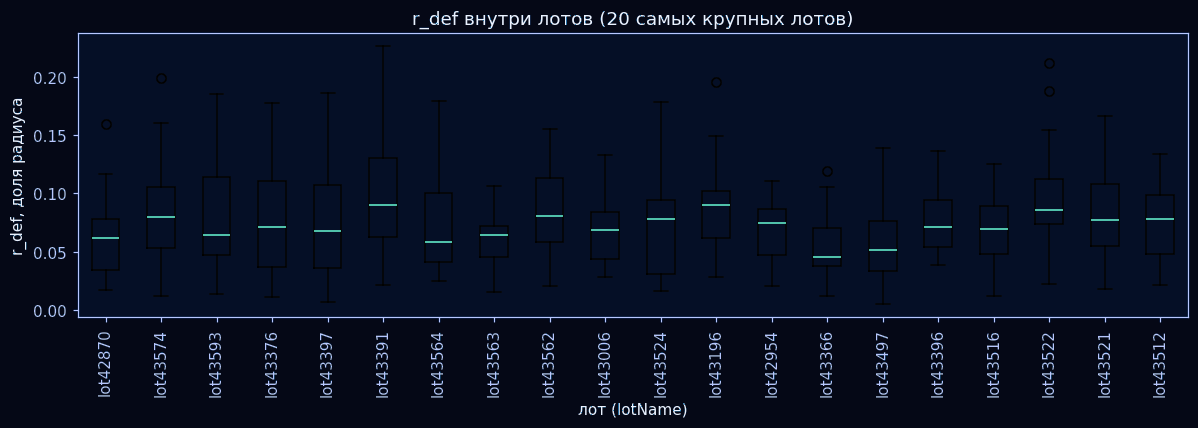

In [47]:
# @title Показать код
top = df["lotName"].value_counts().head(20).index
data = [df.loc[df["lotName"] == lot, "r_def"].dropna().values for lot in top]
fig, ax = plt.subplots(figsize=(11, 4))
bp = ax.boxplot(data, patch_artist=True)
for box in bp['boxes']:
    box.set(facecolor=SPACE_COLORS["violet"], edgecolor=SPACE_COLORS["soft"], alpha=0.48)
for med in bp['medians']:
    med.set(color=SPACE_COLORS["gold"], linewidth=1.6)
for w in bp['whiskers'] + bp['caps']:
    w.set(color=SPACE_COLORS["edge"])
ax.set_xticks(range(1, len(top) + 1), top, rotation=90)
ax.set_xlabel("лот (lotName)")
ax.set_ylabel("r_def, доля радиуса")
ax.set_title("r_def внутри лотов (20 самых крупных лотов)")
style_axis(ax)
plt.tight_layout()
plt.show()


#### 01.4.3. Распределение смещения


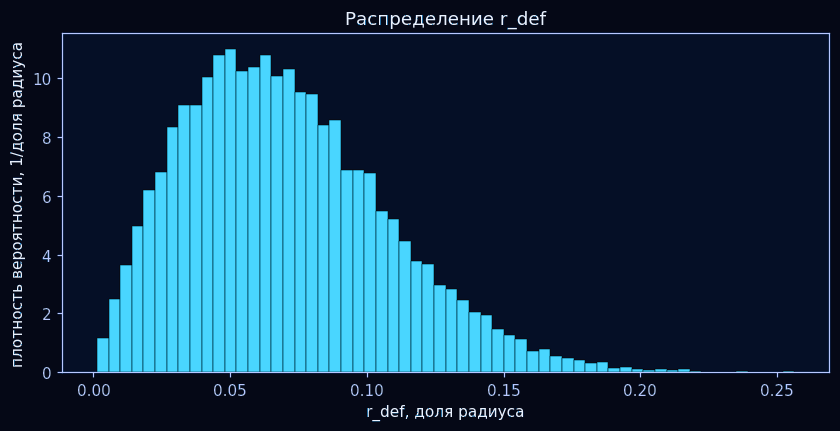

In [48]:
# @title Показать код
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(x, bins=60, density=True, color=SPACE_COLORS["cyan"], edgecolor=SPACE_COLORS["soft"], linewidth=0.3)
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности, 1/доля радиуса")
ax.set_title("Распределение r_def")
style_axis(ax)
plt.show()


#### 01.4.4. Описательные статистики


In [49]:
# @title Показать код
xv = x.to_numpy()
N = len(xv)
pd.Series({
    "n": N, "среднее": xv.mean(), "дисперсия (ddof=1)": xv.var(ddof=1), "ст. отклонение": xv.std(ddof=1),
    "медиана": np.median(xv), "q05": np.quantile(xv, 0.05), "q25": np.quantile(xv, 0.25),
    "q75": np.quantile(xv, 0.75), "q95": np.quantile(xv, 0.95), "min": xv.min(), "max": xv.max(),
    "асимметрия": stats.skew(xv), "эксцесс (избыточный)": stats.kurtosis(xv),
}).round(5)

n                       15881.00000
среднее                     0.07045
дисперсия (ddof=1)          0.00138
ст. отклонение              0.03710
медиана                     0.06608
q05                         0.01802
q25                         0.04246
q75                         0.09373
q95                         0.13835
min                         0.00128
max                         0.25634
асимметрия                  0.66048
эксцесс (избыточный)        0.34166
dtype: float64

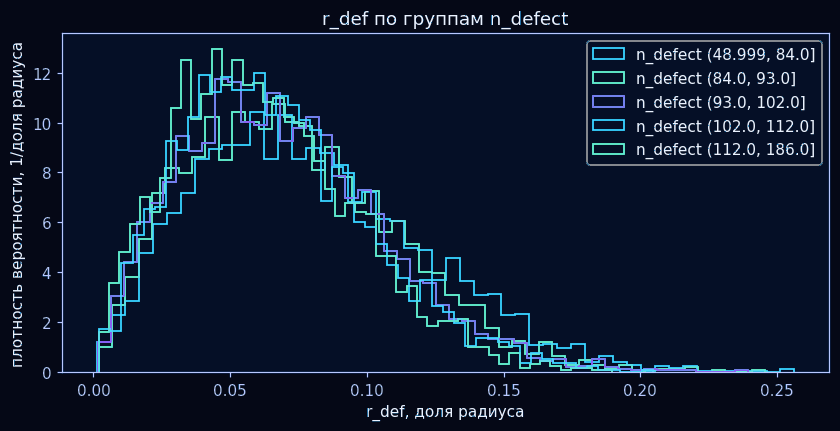

,count,mean,median,std
n_defect,,,,
"(48.999, 84.0]",3443,0.0791,0.0744,0.0413
"(84.0, 93.0]",3115,0.0731,0.0693,0.0378
"(93.0, 102.0]",3293,0.0693,0.0656,0.0362
"(102.0, 112.0]",2879,0.0666,0.0626,0.0341
"(112.0, 186.0]",3151,0.0630,0.0593,0.0327


In [50]:
# @title Показать код
# режимы по числу дефектов: случаев n_defect = 1 нет, группы по квинтилям n_defect
k_grp = pd.qcut(df.loc[x.index, "n_defect"], 5)
fig, ax = plt.subplots(figsize=(9, 4))
for grp, s in x.groupby(k_grp, observed=True):
    ax.hist(s, bins=50, density=True, histtype="step", lw=1.5, label=f"n_defect {grp}")
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности, 1/доля радиуса")
ax.set_title("r_def по группам n_defect")
ax.legend()
style_axis(ax)
plt.show()
x.groupby(k_grp, observed=True).agg(["count", "mean", "median", "std"]).round(4)


#### 01.4.5. Сравнение трёх моделей


Сопоставляем бета-распределение, распределение Рэлея и распределение Вейбулла. Сначала сравниваем модели по AIC, затем отдельно проверяем согласие с наблюдениями.


In [51]:
# @title Показать код
xc = np.clip(xv, EPS, 1 - EPS)
a_hat, b_hat, _, _ = stats.beta.fit(xc, floc=0, fscale=1)
_, s_ray = stats.rayleigh.fit(xv, floc=0)
c_wb, _, s_wb = stats.weibull_min.fit(xv, floc=0)

fits = {
    "бета": {"dist": stats.beta, "args": (a_hat, b_hat, 0, 1), "k": 2, "data": xc,
             "params": f"a={a_hat:.4f}, b={b_hat:.4f}"},
    "Рэлей": {"dist": stats.rayleigh, "args": (0, s_ray), "k": 1, "data": xv,
              "params": f"sigma={s_ray:.5f}"},
    "Вейбулл": {"dist": stats.weibull_min, "args": (c_wb, 0, s_wb), "k": 2, "data": xv,
                "params": f"c={c_wb:.4f}, lambda={s_wb:.5f}"},
}
for f in fits.values():
    f["ll"] = f["dist"].logpdf(f["data"], *f["args"]).sum()
    f["frozen"] = f["dist"](*f["args"])

fit_table = pd.DataFrame({name: {"параметры": f["params"], "число параметров": f["k"], "logL": f["ll"],
                                 "AIC": 2 * f["k"] - 2 * f["ll"],
                                 "среднее модели": f["frozen"].mean(), "1 - F(1)": f["frozen"].sf(1)}
                          for name, f in fits.items()}).T
fit_table["dAIC"] = fit_table["AIC"].astype(float) - fit_table["AIC"].astype(float).min()
fit_table

,параметры,число параметров,logL,AIC,среднее модели,1 - F(1),dAIC
бета,"a=2.9389, b=38.8312",2,30533.937203,-61063.874407,0.07036,0.0,305.465052
Рэлей,sigma=0.05630,1,30685.669729,-61369.339459,0.070565,0.0,0.000000
Вейбулл,"c=1.9857, lambda=0.07950",2,30686.344556,-61368.689112,0.070468,0.0,0.650347


In [52]:
# @title Показать код
# LR-тест: Рэлей (c = 2) вложен в Вейбулл
lr_rw = 2 * (fits["Вейбулл"]["ll"] - fits["Рэлей"]["ll"])
p_rw = stats.chi2.sf(lr_rw, df=1)
print(f"LR Рэлей vs Вейбулл = {lr_rw:.3f}, p = {p_rw:.3e}, c Вейбулла = {c_wb:.4f}")

LR Рэлей vs Вейбулл = 1.350, p = 2.453e-01, c Вейбулла = 1.9857


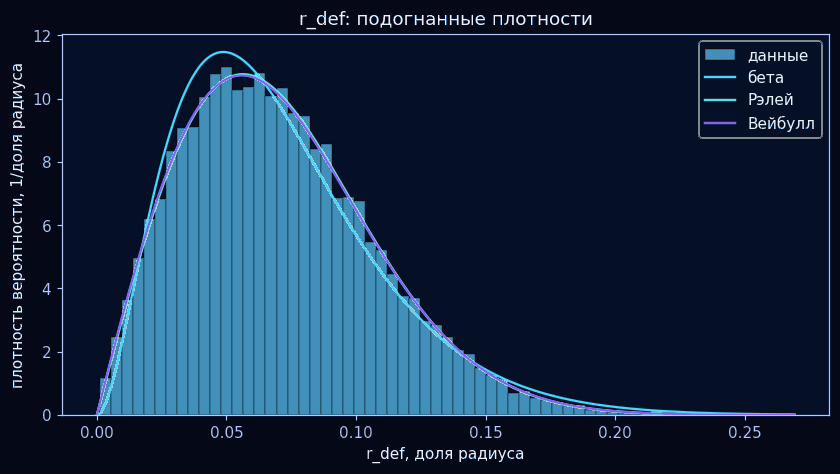

In [53]:
# @title Показать код
grid = np.linspace(0, xv.max() * 1.05, 400)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(xv, bins=60, density=True, color=SPACE_COLORS["cyan"], edgecolor=SPACE_COLORS["soft"], linewidth=0.3, alpha=0.28, label="данные")
for name, f in fits.items():
    ax.plot(grid, f["frozen"].pdf(grid), lw=1.8, label=name)
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности, 1/доля радиуса")
ax.set_title("r_def: подогнанные плотности")
ax.legend()
style_axis(ax)
plt.show()


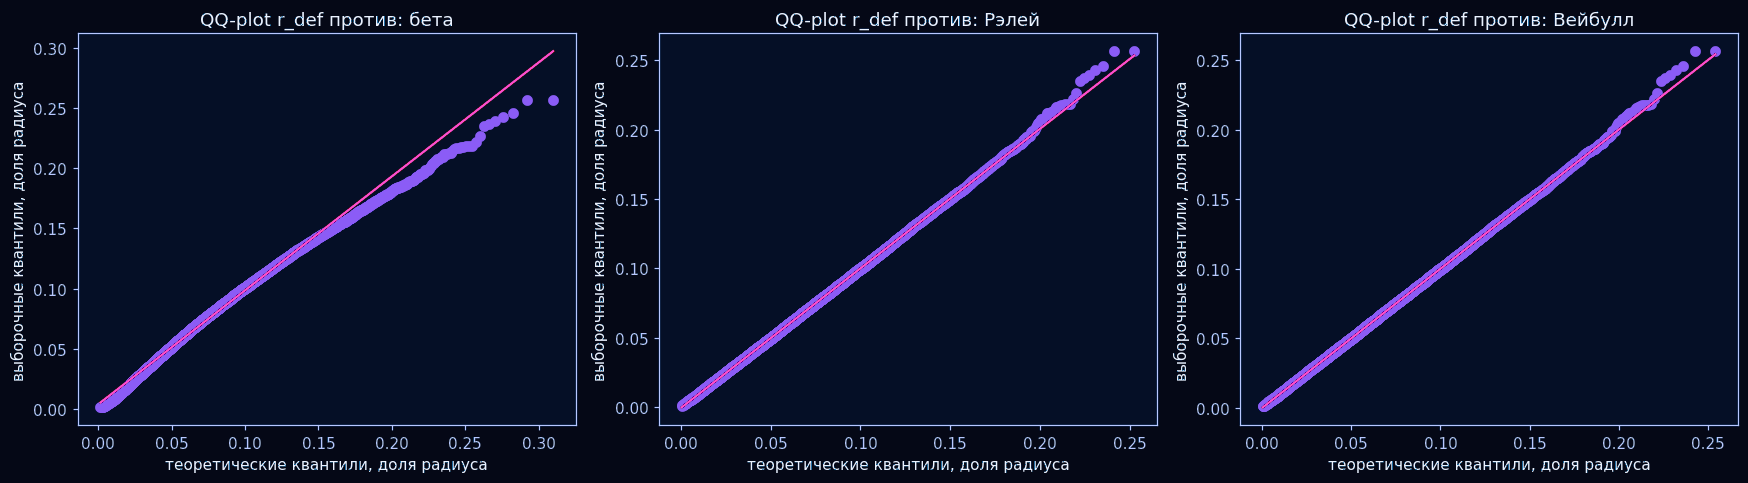

In [54]:
# @title Показать код
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
qq_cols = [SPACE_COLORS["violet"], SPACE_COLORS["cyan"], SPACE_COLORS["gold"]]
for ax, (name, f), qcol in zip(axes, fits.items(), qq_cols):
    stats.probplot(f["data"], dist=f["dist"], sparams=f["args"], plot=ax)
    style_probplot(ax, point_color=qcol, line_color=SPACE_COLORS["magenta"])
    ax.set_title(f"QQ-plot r_def против: {name}")
    ax.set_xlabel("теоретические квантили, доля радиуса")
    ax.set_ylabel("выборочные квантили, доля радиуса")
plt.tight_layout()
plt.show()


**Почему для генератора выбрали Рэлея.** На квантильных графиках проверяем, где данные отклоняются от модели. По AIC Рэлея и Вейбулла разделяет меньше единицы, а критерий согласия для Рэлея не дал оснований его отвергнуть. Для генератора выбрали Рэлея: здесь достаточно оценить один параметр масштаба.


#### 01.4.6. Модель равномерных дефектов


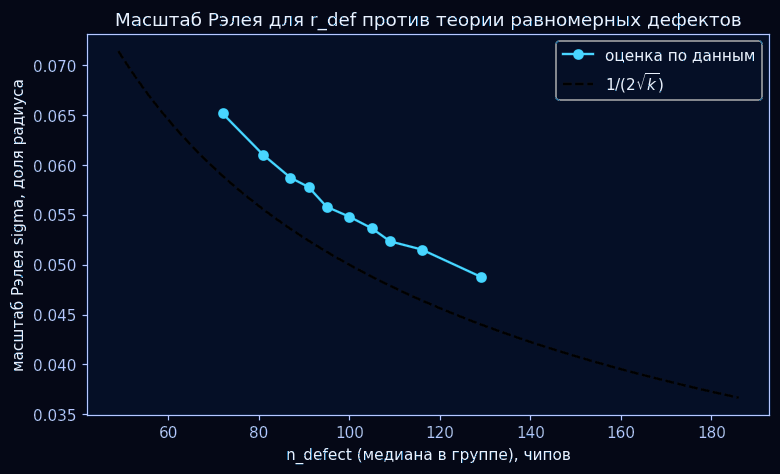

,группа n_defect,размер,медиана k,sigma Рэлея (ММП),теория 1/(2*sqrt(k)),отношение
0,"(48.999, 77.0]",1698,72.0,0.06518,0.05893,1.10616
1,"(77.0, 84.0]",1745,81.0,0.06102,0.05556,1.09836
2,"(84.0, 88.0]",1383,87.0,0.05874,0.05361,1.09569
3,"(88.0, 93.0]",1732,91.0,0.05780,0.05241,1.10270
4,"(93.0, 97.0]",1507,95.0,0.05581,0.05130,1.08803
5,"(97.0, 102.0]",1786,100.0,0.05482,0.05000,1.09642
6,"(102.0, 106.0]",1278,105.0,0.05365,0.04880,1.09952
7,"(106.0, 112.0]",1601,109.0,0.05235,0.04789,1.09311
8,"(112.0, 121.0]",1618,116.0,0.05153,0.04642,1.10989
9,"(121.0, 186.0]",1533,129.0,0.04880,0.04402,1.10856


In [55]:
# @title Показать код
# масштаб Рэлея по группам n_defect против 1/(2*sqrt(k))
kd = df.loc[x.index, "n_defect"]
grp = pd.qcut(kd, 10)
ray_rows = []
for gname, s in x.groupby(grp, observed=True):
    k_med = kd[s.index].median()
    ray_rows.append({"группа n_defect": str(gname), "размер": len(s), "медиана k": k_med,
                     "sigma Рэлея (ММП)": np.sqrt((s**2).mean() / 2),
                     "теория 1/(2*sqrt(k))": 1 / (2 * np.sqrt(k_med))})
ray_tab = pd.DataFrame(ray_rows)
ray_tab["отношение"] = ray_tab["sigma Рэлея (ММП)"] / ray_tab["теория 1/(2*sqrt(k))"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ray_tab["медиана k"], ray_tab["sigma Рэлея (ММП)"], "o-", linewidth=1.8, color=SPACE_COLORS["cyan"], label="оценка по данным")
kk = np.linspace(kd.min(), kd.max(), 200)
ax.plot(kk, 1 / (2 * np.sqrt(kk)), linestyle="--", linewidth=1.8, color=SPACE_COLORS["magenta"], label=r"$1/(2\sqrt{k})$")
ax.set_xlabel("n_defect (медиана в группе), чипов")
ax.set_ylabel("масштаб Рэлея sigma, доля радиуса")
ax.set_title("Масштаб Рэлея для r_def против теории равномерных дефектов")
ax.legend()
style_axis(ax)
plt.show()
ray_tab.round(5)


z: среднее = 1.3816 (Rayleigh(1): 1.2533), sigma ММП = 1.1002


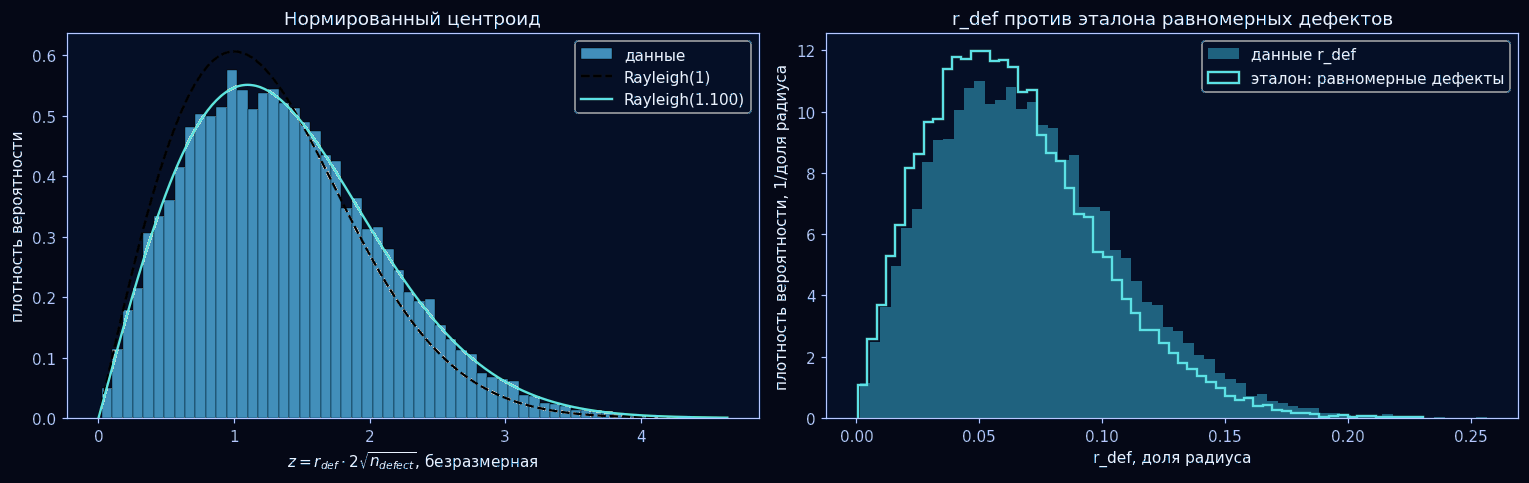

In [56]:
# @title Показать код
# нормированный центроид z = r_def * 2*sqrt(n_defect): при равномерных дефектах ~ Rayleigh(1)
z = (x * 2 * np.sqrt(kd)).to_numpy()
_, s_z = stats.rayleigh.fit(z, floc=0)
# эталонная смесь: для каждой пластины Rayleigh(1/(2*sqrt(k_i)))
ref = rng.rayleigh(1 / (2 * np.sqrt(kd.to_numpy())))
print(f"z: среднее = {z.mean():.4f} (Rayleigh(1): {np.sqrt(np.pi / 2):.4f}), sigma ММП = {s_z:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
gz = np.linspace(0, z.max(), 300)
axes[0].hist(z, bins=60, density=True, color=SPACE_COLORS["cyan"], edgecolor=SPACE_COLORS["soft"], linewidth=0.3, alpha=0.3, label="данные")
axes[0].plot(gz, stats.rayleigh.pdf(gz), linestyle="--", linewidth=1.7, color=SPACE_COLORS["magenta"], label="Rayleigh(1)")
axes[0].plot(gz, stats.rayleigh.pdf(gz, scale=s_z), linewidth=1.8, color=SPACE_COLORS["gold"], label=f"Rayleigh({s_z:.3f})")
axes[0].set_xlabel(r"$z = r_{def}\cdot 2\sqrt{n_{defect}}$, безразмерная")
axes[0].set_ylabel("плотность вероятности")
axes[0].set_title("Нормированный центроид")
axes[0].legend()
style_axis(axes[0])
axes[1].hist(xv, bins=60, density=True, histtype="stepfilled", alpha=0.26, color=SPACE_COLORS["violet"], label="данные r_def")
axes[1].hist(ref, bins=60, density=True, histtype="step", lw=1.6, color=SPACE_COLORS["mint"], label="эталон: равномерные дефекты")
axes[1].set_xlabel("r_def, доля радиуса")
axes[1].set_ylabel("плотность вероятности, 1/доля радиуса")
axes[1].set_title("r_def против эталона равномерных дефектов")
axes[1].legend()
style_axis(axes[1])
plt.tight_layout()
plt.show()


**Что показало сравнение с равномерным эталоном.** С ростом числа дефектов масштаб смещения уменьшается, как и в эталонной модели. При этом оценённый масштаб в группах примерно на 9–11% выше эталона. Это показывает, где простое предположение о равномерных дефектах расходится с данными.


#### 01.4.7. Модели распределения


В бета-модели значения лежат на $[0,1]$. В моделях Рэлея и Вейбулла шкала начинается с нуля и не имеет верхней границы. Распределение Рэлея соответствует распределению Вейбулла при параметре формы $c=2$ и соответствующем масштабе. На графиках квантилей смотрим, где модели расходятся с данными.

Плотность Рэлея при $r\ge0$ равна $f(r)=\frac{r}{\sigma^2}e^{-r^2/(2\sigma^2)}$. Для Вейбулла $f(r)=\frac{k}{a}(r/a)^{k-1}e^{-(r/a)^k}$ при $r\ge0$, а для бета-распределения $f(r)=r^{\alpha-1}(1-r)^{\beta-1}/B(\alpha,\beta)$ при $0<r<1$.


#### 01.4.8. Преобразования шкалы


После преобразования сравниваем форму распределения. Смещение в долях радиуса читаем по графику в исходной шкале.


In [57]:
# @title Показать код
x_bc, lam_bc = stats.boxcox(xv)
print(f"Бокс-Кокс: lambda = {lam_bc:.4f}")
transforms = {
    "исходные": xv,
    "z-score": (xv - xv.mean()) / xv.std(ddof=1),
    "логит": np.log(xc / (1 - xc)),
    "Бокс-Кокс": x_bc,
}
pd.DataFrame({name: {"асимметрия": stats.skew(t), "эксцесс (избыточный)": stats.kurtosis(t)}
              for name, t in transforms.items()}).T.round(4)

Бокс-Кокс: lambda = 0.5187


,асимметрия,эксцесс (избыточный)
исходные,0.6605,0.3417
z-score,0.6605,0.3417
логит,-0.9578,1.5965
Бокс-Кокс,-0.0363,-0.2608


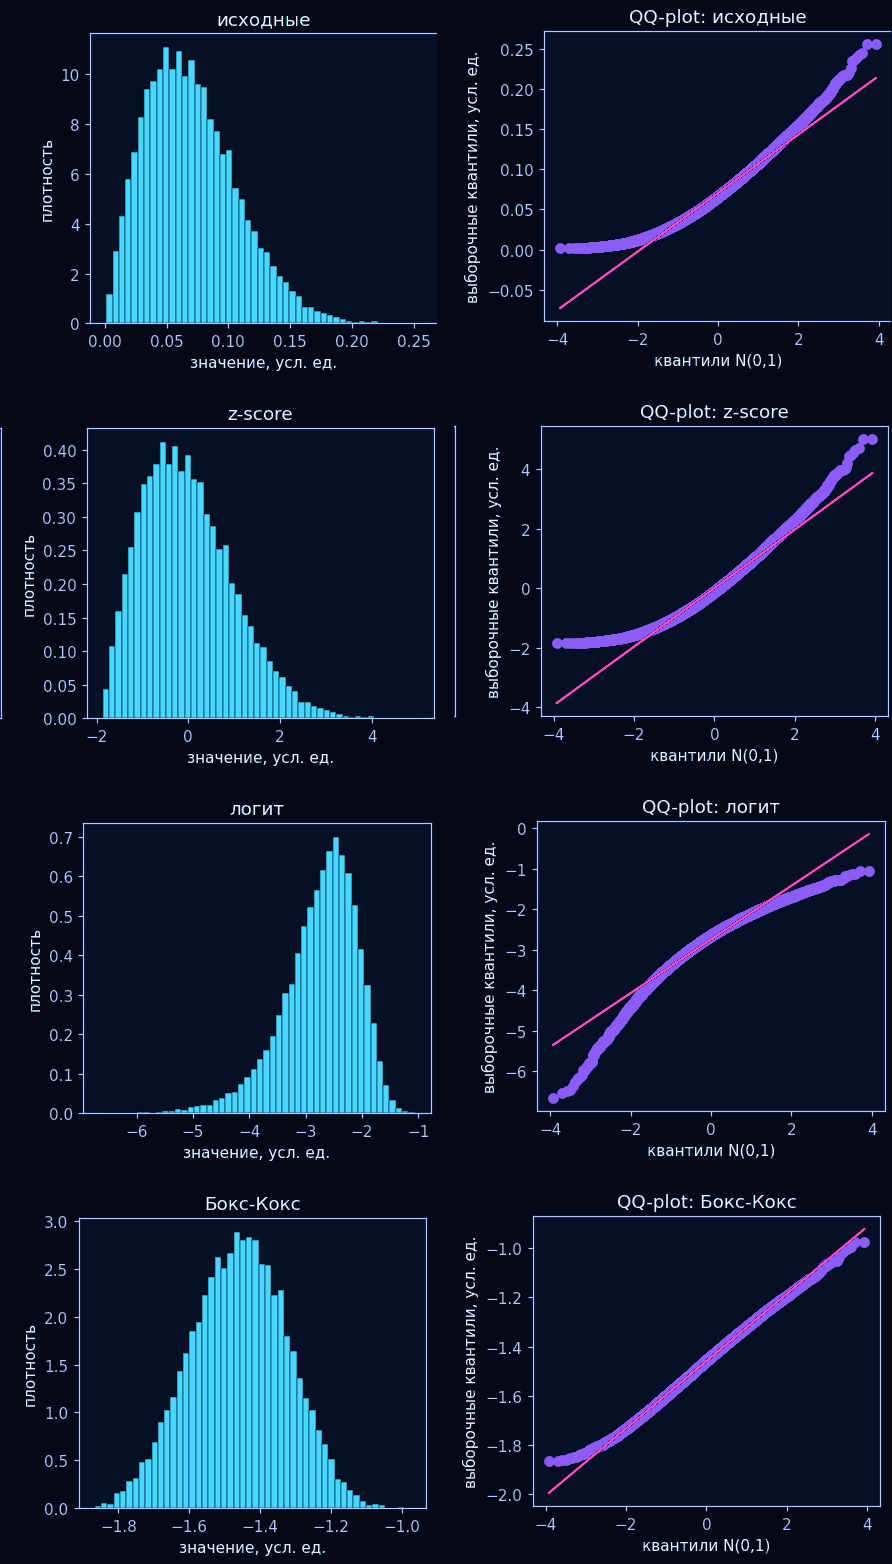

In [58]:
# @title Показать код
fig, axes = plt.subplots(len(transforms), 2, figsize=(12.6, 3.9 * len(transforms)))
hist_colors = [SPACE_COLORS["cyan"], SPACE_COLORS["teal"], SPACE_COLORS["violet"], SPACE_COLORS["gold"]]
qq_colors = [SPACE_COLORS["violet"], SPACE_COLORS["cyan"], SPACE_COLORS["magenta"], SPACE_COLORS["gold"]]
for j, (name, t) in enumerate(transforms.items()):
    hax, qax = axes[j, 0], axes[j, 1]
    hax.hist(t, bins=50, density=True, color=hist_colors[j % len(hist_colors)], edgecolor=SPACE_COLORS["soft"], linewidth=0.35)
    hax.set_title(name)
    hax.set_xlabel("Смещение, доля радиуса" if name == "исходные" else "преобразованная шкала (безразмерная)")
    hax.set_ylabel("плотность")
    style_axis(hax)
    stats.probplot(t, dist="norm", plot=qax)
    style_probplot(qax, point_color=qq_colors[j % len(qq_colors)], line_color=SPACE_COLORS["magenta"])
    qax.set_title(f"QQ-plot: {name}")
    qax.set_xlabel("квантили N(0,1)")
    qax.set_ylabel("выборочные квантили, смещение, доля радиуса" if name == "исходные" else "выборочные квантили (безразмерные)")
plt.tight_layout()
plt.show()


#### 01.4.9. Проверка оценок на выборках


In [59]:
# @title Показать код
# выборки с возвращением из всей совокупности, N_REP повторов на каждый размер
sizes = np.unique(np.logspace(1, np.log10(N), 15).astype(int))
true_vals = {"среднее": xv.mean(), "дисперсия": xv.var(ddof=1), "медиана": np.median(xv)}

rows = []
for n in sizes:
    est = np.array([[s.mean(), s.var(ddof=1), np.median(s)]
                    for s in (rng.choice(xv, n, replace=True) for _ in range(N_REP))])
    for j, name in enumerate(true_vals):
        q05, q50, q95 = np.quantile(est[:, j], [0.05, 0.5, 0.95])
        rows.append({"n": n, "оценка": name, "q05": q05, "медиана": q50, "q95": q95})
cons = pd.DataFrame(rows)
cons["ширина 5-95%"] = cons["q95"] - cons["q05"]
cons.pivot(index="n", columns="оценка", values="ширина 5-95%").round(6)

оценка,дисперсия,медиана,среднее
n,,,
10,0.001908,0.048974,0.041685
16,0.001630,0.038116,0.027343
28,0.001483,0.031888,0.023019
48,0.000927,0.022543,0.015251
82,0.000741,0.015445,0.015263
139,0.000503,0.012143,0.009408
235,0.000530,0.010673,0.008591
398,0.000334,0.008705,0.006139
674,0.000270,0.005859,0.004618


#### 01.4.10. Состоятельность оценок


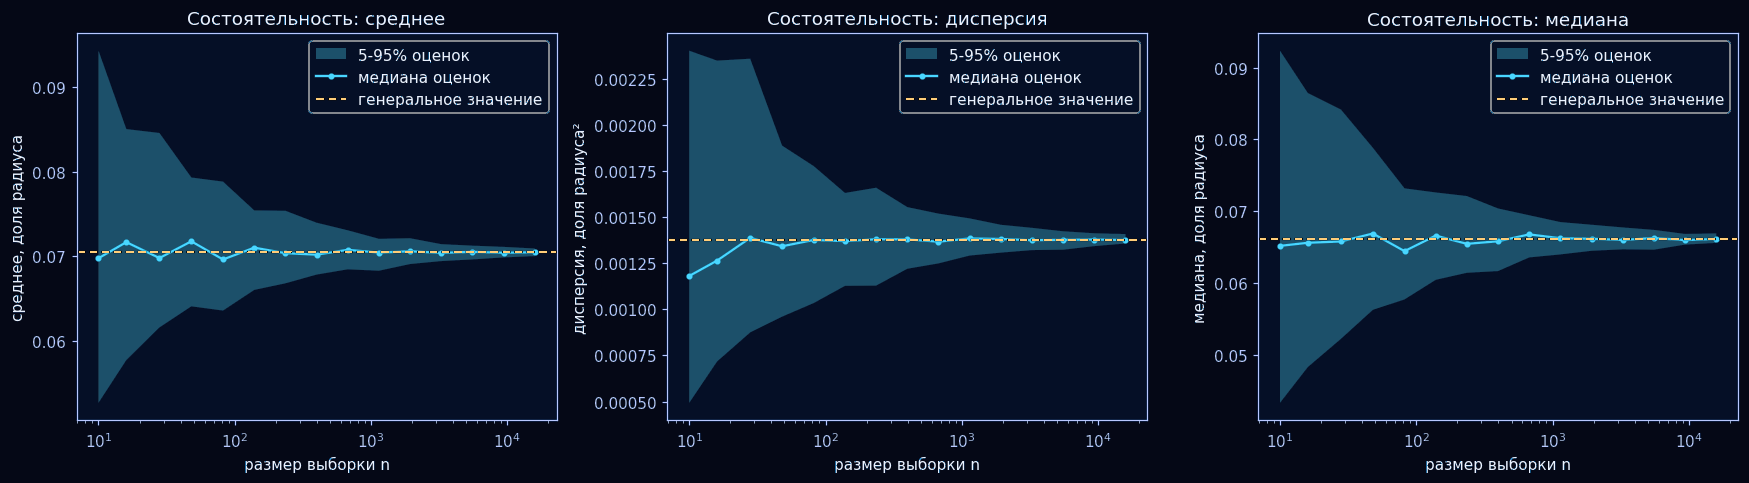

In [60]:
# @title Показать код
units = {"среднее": "доля радиуса", "дисперсия": "доля радиуса²", "медиана": "доля радиуса"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, true_vals):
    cc = cons[cons["оценка"] == name]
    ax.fill_between(cc["n"], cc["q05"], cc["q95"], alpha=0.3, label="5-95% оценок")
    ax.semilogx(cc["n"], cc["медиана"], "o-", ms=3, label="медиана оценок")
    ax.axhline(true_vals[name], color=SPACE_COLORS["gold"], ls="--", lw=1.5, label="генеральное значение")
    ax.set_xlabel("размер выборки n")
    ax.set_ylabel(f"{name}, {units[name]}")
    ax.set_title(f"Состоятельность: {name}")
    ax.legend()
plt.tight_layout()
plt.show()

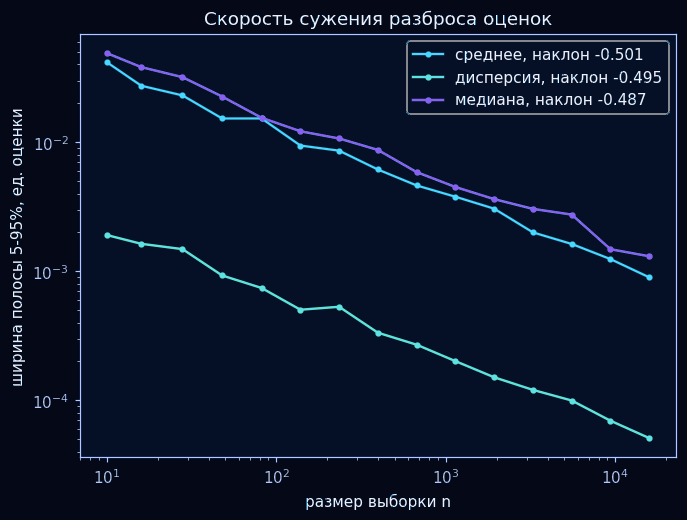

среднее     -0.5008
дисперсия   -0.4953
медиана     -0.4874
Name: наклон, dtype: float64

In [61]:
# @title Показать код
fig, ax = plt.subplots(figsize=(7, 5))
slopes = {}
for name in true_vals:
    cc = cons[(cons["оценка"] == name) & (cons["ширина 5-95%"] > 0)]
    slopes[name] = np.polyfit(np.log10(cc["n"]), np.log10(cc["ширина 5-95%"]), 1)[0]
    ax.loglog(cc["n"], cc["ширина 5-95%"], "o-", ms=3, label=f"{name}, наклон {slopes[name]:.3f}")
ax.set_xlabel("размер выборки n")
ax.set_ylabel("ширина полосы 5-95%, ед. оценки")
ax.set_title("Скорость сужения разброса оценок")
ax.legend()
plt.show()
pd.Series(slopes, name="наклон").round(4)

#### 01.4.11. Выборки с возвращением и без


In [62]:
# @title Показать код
s_with = x.sample(N_SAMPLE, replace=True, random_state=SEED)
s_without = x.sample(N_SAMPLE, replace=False, random_state=SEED)

def summary(s):
    return pd.Series({"n": len(s), "среднее": s.mean(), "дисперсия": s.var(ddof=1),
                      "q05": s.quantile(0.05), "q25": s.quantile(0.25), "медиана": s.median(),
                      "q75": s.quantile(0.75), "q95": s.quantile(0.95)})

pd.DataFrame({"генеральная": summary(x), "с возвращением": summary(s_with),
              "без возвращения": summary(s_without)}).round(5)

,генеральная,с возвращением,без возвращения
n,15881.00000,1000.00000,1000.00000
среднее,0.07045,0.07078,0.07141
дисперсия,0.00138,0.00133,0.00134
q05,0.01802,0.01735,0.01927
q25,0.04246,0.04347,0.04432
медиана,0.06608,0.06828,0.06634
q75,0.09373,0.09291,0.09542
q95,0.13835,0.13792,0.13919


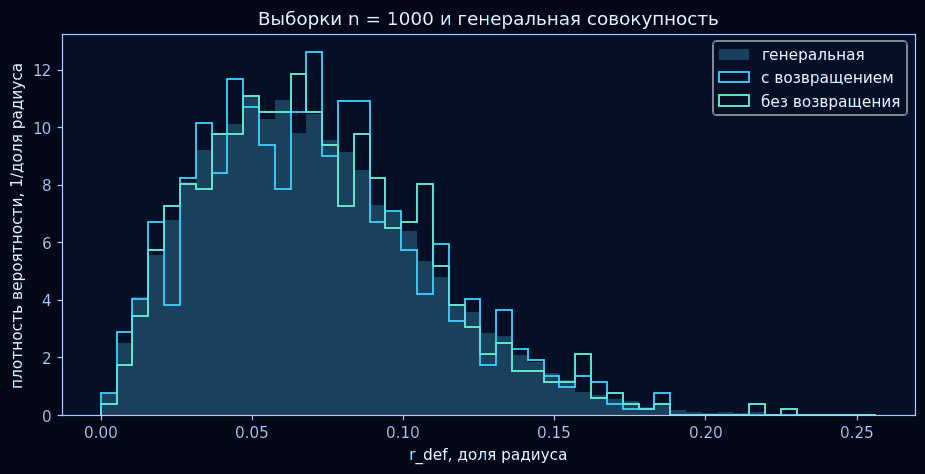

In [63]:
# @title Показать код
bins = np.linspace(0, xv.max(), 50)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(x, bins=bins, density=True, histtype="stepfilled", alpha=0.22, color=SPACE_COLORS["cyan"], label="генеральная")
ax.hist(s_with, bins=bins, density=True, histtype="step", lw=1.5, color=SPACE_COLORS["violet"], label="с возвращением")
ax.hist(s_without, bins=bins, density=True, histtype="step", lw=1.5, color=SPACE_COLORS["magenta"], label="без возвращения")
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности, 1/доля радиуса")
ax.set_title(f"Выборки n = {N_SAMPLE} и генеральная совокупность")
ax.legend()
style_axis(ax)
plt.show()


In [64]:
# @title Показать код
complement = x.drop(s_without.index)
for name, s, ref_s in [("с возвращением vs генеральная", s_with, x),
                       ("без возвращения vs дополнение", s_without, complement)]:
    r = stats.ks_2samp(s, ref_s)
    print(f"KS {name}: D = {r.statistic:.4f}, p = {r.pvalue:.4f}")

# квантили выборок против генеральной
qs = [0.05, 0.25, 0.5, 0.75, 0.95]
pd.DataFrame({"генеральная": x.quantile(qs), "с возвращением": s_with.quantile(qs),
              "без возвращения": s_without.quantile(qs)}).round(5)

KS с возвращением vs генеральная: D = 0.0256, p = 0.5593
KS без возвращения vs дополнение: D = 0.0272, p = 0.4849


,генеральная,с возвращением,без возвращения
0.05,0.01802,0.01735,0.01927
0.25,0.04246,0.04347,0.04432
0.50,0.06608,0.06828,0.06634
0.75,0.09373,0.09291,0.09542
0.95,0.13835,0.13792,0.13919


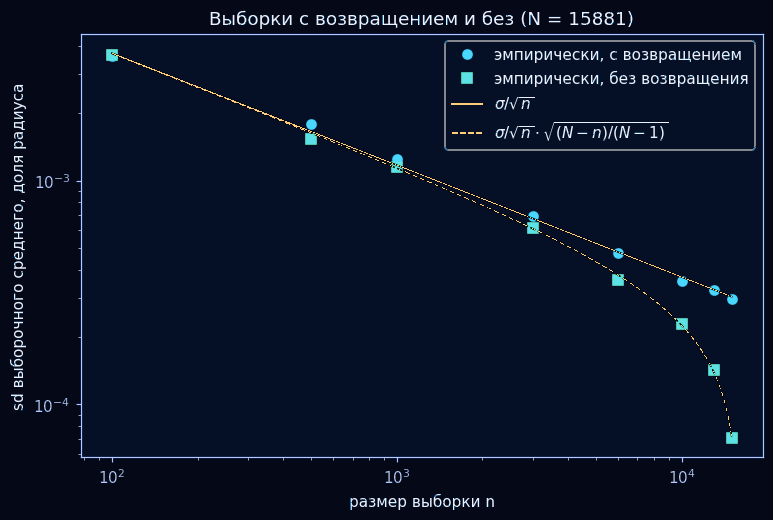

,n,n/N,sd с возвр.,sd без возвр.,теория sigma/sqrt(n),теория с FPC
0,100,0.006297,0.003609,0.003633,0.003710,0.003698
1,500,0.031484,0.001784,0.001527,0.001659,0.001633
2,1000,0.062968,0.001247,0.001151,0.001173,0.001136
3,3000,0.188905,0.000696,0.000611,0.000677,0.000610
4,6000,0.377810,0.000476,0.000361,0.000479,0.000378
5,10000,0.629683,0.000355,0.000228,0.000371,0.000226
6,13000,0.818588,0.000323,0.000143,0.000325,0.000139
7,15000,0.944525,0.000297,0.000071,0.000303,0.000071


In [65]:
# @title Показать код
# Монте-Карло: sd выборочного среднего с возвращением и без против теории
sigma = xv.std(ddof=0)
n_grid = np.array([100, 500, 1000, 3000, 6000, 10000, 13000, 15000])
mc = []
for n in n_grid:
    m_with = [rng.choice(xv, n, replace=True).mean() for _ in range(N_MC)]
    m_without = [rng.choice(xv, n, replace=False).mean() for _ in range(N_MC)]
    mc.append({"n": n, "n/N": n / N, "sd с возвр.": np.std(m_with, ddof=1),
               "sd без возвр.": np.std(m_without, ddof=1),
               "теория sigma/sqrt(n)": sigma / np.sqrt(n),
               "теория с FPC": sigma / np.sqrt(n) * np.sqrt((N - n) / (N - 1))})
mc = pd.DataFrame(mc)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(mc["n"], mc["sd с возвр."], "o", label="эмпирически, с возвращением")
ax.loglog(mc["n"], mc["sd без возвр."], "s", label="эмпирически, без возвращения")
nn = np.linspace(n_grid.min(), n_grid.max(), 400)
ax.loglog(nn, sigma / np.sqrt(nn), "-", lw=1.6, color=SPACE_COLORS["gold"], label=r"$\sigma/\sqrt{n}$")
ax.loglog(nn, sigma / np.sqrt(nn) * np.sqrt((N - nn) / (N - 1)), "--", lw=1.6, color=SPACE_COLORS["gold"],
          label=r"$\sigma/\sqrt{n}\cdot\sqrt{(N-n)/(N-1)}$")
ax.set_xlabel("размер выборки n")
ax.set_ylabel("sd выборочного среднего, доля радиуса")
ax.set_title(f"Выборки с возвращением и без (N = {N})")
ax.legend()
plt.show()
mc.round(6)

#### 01.4.12. Проверка гипотез

По графикам видно, где расходятся наблюдаемые и теоретические квантили. Теперь проверим, насколько заметны эти расхождения по формальным критериям.


In [66]:
# @title Показать код
# обычный KS с подогнанными параметрами и goodness_of_fit (Монте-Карло) на подвыборке
sub = rng.choice(xv, N_GOF, replace=False)
known = {"бета": {"loc": 0, "scale": 1}, "Рэлей": {"loc": 0}, "Вейбулл": {"loc": 0}}
gof_rows = []
for name, f in fits.items():
    data_full = f["data"]
    data_sub = np.clip(sub, EPS, 1 - EPS) if name == "бета" else sub
    ks_naive = stats.kstest(data_full, f["dist"].cdf, args=f["args"])
    row = {"KS D (вся выборка)": ks_naive.statistic, "KS p наивный": ks_naive.pvalue}
    for stat in ["ks", "ad"]:
        res = stats.goodness_of_fit(f["dist"], data_sub, known_params=known[name], statistic=stat,
                                    n_mc_samples=B_GOF, rng=rng)
        row[f"{stat.upper()} стат. (подвыборка)"] = res.statistic
        row[f"{stat.upper()} p Монте-Карло"] = res.pvalue
    gof_rows.append(pd.Series(row, name=name))
print(f"подвыборка N_GOF = {N_GOF}, n_mc_samples = {B_GOF}")
pd.DataFrame(gof_rows)

подвыборка N_GOF = 2000, n_mc_samples = 200


,KS D (вся выборка),KS p наивный,KS стат. (подвыборка),KS p Монте-Карло,AD стат. (подвыборка),AD p Монте-Карло
бета,0.028515,1.188875e-11,0.026107,0.004975,2.586944,0.004975
Рэлей,0.005671,6.844302e-01,0.019382,0.253731,0.698266,0.298507
Вейбулл,0.003374,9.933423e-01,0.010898,0.865672,0.333428,0.487562


In [67]:
# @title Показать код
# chi2 согласия по равновероятным интервалам, ddof = число параметров
chi_rows = []
for name, f in fits.items():
    edges = f["frozen"].ppf(np.linspace(0, 1, K_CHI2 + 1))
    O = np.histogram(f["data"], bins=edges)[0]
    E = np.full(K_CHI2, len(f["data"]) / K_CHI2)
    stat, p = stats.chisquare(O, E, ddof=f["k"])
    chi_rows.append({"модель": name, "chi2": stat, "df": K_CHI2 - 1 - f["k"], "p-value": p,
                     "min O": O.min(), "max O": O.max()})
chi_tab = pd.DataFrame(chi_rows).set_index("модель")
chi_tab

,chi2,df,p-value,min O,max O
модель,,,,,
бета,184.228890,17,4.139126e-30,608,934
Рэлей,12.083559,18,8.428935e-01,746,829
Вейбулл,9.315471,17,9.298418e-01,757,830


In [68]:
# @title Показать код
# Манн-Уитни Training против Test: r_def и нормированный центроид z
lab = df.loc[x.index, "trianTestLabel"].to_numpy()
mw_rows = []
for name, vals in [("r_def", xv), ("z = r_def*2*sqrt(n_defect)", z),
                   ("n_defect", df.loc[x.index, "n_defect"].to_numpy())]:
    tr, te = vals[lab == "Training"], vals[lab == "Test"]
    r = stats.mannwhitneyu(tr, te, alternative="two-sided", method="asymptotic")
    mw_rows.append({"величина": name, "n Training": len(tr), "n Test": len(te),
                    "медиана Training": np.median(tr), "медиана Test": np.median(te),
                    "U": r.statistic, "p-value": r.pvalue, "U/(n1*n2)": r.statistic / (len(tr) * len(te))})
mw_tab = pd.DataFrame(mw_rows).set_index("величина")
mw_tab

,n Training,n Test,медиана Training,медиана Test,U,p-value,U/(n1*n2)
величина,,,,,,,
r_def,13005,2876,0.065133,0.071379,17033501.5,6.602348e-14,0.455412
z = r_def*2*sqrt(n_defect),13005,2876,1.294930,1.350867,17950675.0,7.428864e-04,0.479934
n_defect,13005,2876,99.000000,90.000000,24702768.5,2.618588e-160,0.660460


#### 01.4.13. Сводная таблица результатов


In [69]:
# @title Показать код
best = fit_table["AIC"].astype(float).idxmin()
summary_tab = pd.Series({
    "пластин (n)": N,
    "доля NaN": x_all.isna().mean(),
    "лотов": df["lotName"].nunique(),
    "среднее r_def": xv.mean(),
    "дисперсия r_def": xv.var(ddof=1),
    "медиана r_def": np.median(xv),
    "асимметрия": stats.skew(xv),
    "эксцесс": stats.kurtosis(xv),
    "внутрилотовая дисперсия": var_within,
    "межлотовая дисперсия": var_between,
    "ICC": icc,
    "бета a": a_hat, "бета b": b_hat,
    "Рэлей sigma": s_ray,
    "Вейбулл c": c_wb, "Вейбулл lambda": s_wb,
    "AIC бета": fit_table.loc["бета", "AIC"],
    "AIC Рэлей": fit_table.loc["Рэлей", "AIC"],
    "AIC Вейбулл": fit_table.loc["Вейбулл", "AIC"],
    "лучшая по AIC": best,
    "LR Рэлей vs Вейбулл": lr_rw, "p LR": p_rw,
    "теория sigma 1/(2*sqrt(медиана k))": 1 / (2 * np.sqrt(kd.median())),
    "z: sigma Рэлея": s_z,
    "Бокс-Кокс lambda": lam_bc,
    f"chi2 ({best})": chi_tab.loc[best, "chi2"],
    f"p chi2 ({best})": chi_tab.loc[best, "p-value"],
    "Манн-Уитни p (r_def)": mw_tab.loc["r_def", "p-value"],
    "Манн-Уитни U/(n1*n2) (r_def)": mw_tab.loc["r_def", "U/(n1*n2)"],
}, dtype=object)
summary_tab.map(lambda v: f"{v:.6g}" if isinstance(v, (float, np.floating)) else v).to_frame("значение")

,значение
пластин (n),15881
доля NaN,0
лотов,715
среднее r_def,0.0704534
дисперсия r_def,0.00137648
медиана r_def,0.0660767
асимметрия,0.660484
эксцесс,0.341657
внутрилотовая дисперсия,0.00133402
межлотовая дисперсия,0.000102068


#### 01.4.14. Выводы


На 15 881 пластине медианное смещение центра дефектов составило 6,61% нормирующего радиуса. По AIC распределение Рэлея немного опередило распределение Вейбулла. Критерий согласия χ² для модели Рэлея дал p ≈ 0,843, поэтому на уровне 5% гипотезу о согласии не отвергаем.


<a id="appstat-sprint1-results"></a>

### 01.5. Выводы первого спринта


Полный набор из 15 881 пластины служит эталоном для сравнения подвыборок. Выводы относятся к отобранным пластинам WM-811K, которые использовала команда.


В центре и у края количество дефектов меняется от пластины к пластине. Проверки показали слабую положительную связь между счётчиками. В центре наблюдается перерассеяние. Медианное смещение центра дефектов составило 6,61% нормирующего радиуса. Из трёх рассмотренных моделей наименьший AIC получен у распределения Рэлея.


<a id="appstat-sprint1-criteria"></a>

### 01.6. cat_mark_table


<a id="cat_mark_table"></a>

[Категория lab.de.01 в журнале](https://docs.google.com/spreadsheets/d/1ATBKHrTjZsGwQ-6YRP0aZvUvSSKBNRze7YlqbAEJC60/edit?gid=1577767658#gid=1577767658)

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| lab.de.01 | [Оглавление](#scrollTo=f335250b) | | Индексы и переходы к разделам |
| lab.de.01 | [Данные и оформление графиков](#scrollTo=7330897d) | | Сворачиваемые ячейки с кодом и единое оформление графиков |
| lab.de.01 | [График связи центра и края](#scrollTo=70a65849) | | Подписаны обе оси, единица измерения — чипы. Доли, число чипов и доля радиуса подписаны на соответствующих графиках |
| lab.de.01 | [Математическая часть анализа центра](#scrollTo=02aca094) | | Формулы распределений и стандартизация в LaTeX |
| lab.de.01 | [Выборки для центра](#scrollTo=ed41ed8f) | | Визуальная проверка устойчивости среднего |
| lab.de.01 | [Квантильные графики для смещения](#scrollTo=0f3e9fb9) | | Сравнение моделей на одной шкале |


<a id="appstat-sprint2"></a>

## 02. Второй спринт. Генератор случайных чисел


<a id="appstat-generator"></a>

### 02.1. Генератор смещения центра дефектов


#### 02.1.1. Как получаем случайное смещение

По итогам первого спринта выбрали распределение Рэлея для `r_def`. Его функция распределения при $r\ge0$ равна $F(r)=1-\exp[-r^2/(2\sigma^2)]$. Оценка масштаба $\hat\sigma=\sqrt{\frac1{2n}\sum_i r_i^2}$ получена по полному набору пластин.

Генерируем $u$ равномерно на $[0,1)$ и решаем уравнение $F(r)=u$. Получаем $r=\hat\sigma\sqrt{-2\ln(1-u)}$. На рисунке проверяем одно случайное число, а по таблице и двум графикам сравниваем целые выборки.

Формула обратной функции приведена в справочнике [NIST, Rayleigh Percent Point Function](https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/rayppf.htm).


#### 02.1.2. Сравнение с реальными пластинами


Масштаб Рэлея: 0.05630; максимальная разница эмпирических CDF: 0.0047


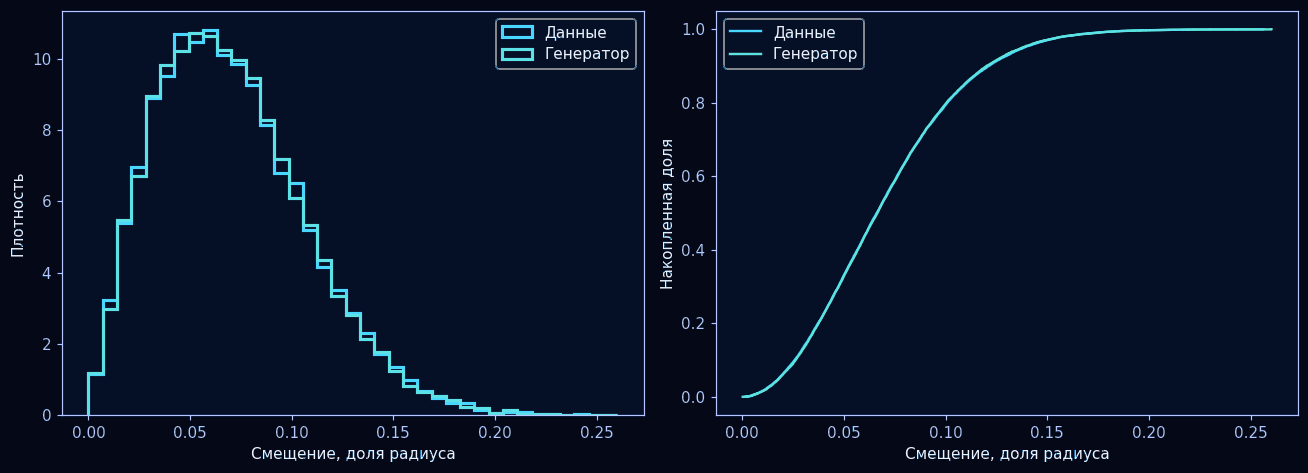

,Данные,Генератор,Разница
Среднее,0.070453,0.070438,-0.000016
Дисперсия,0.001376,0.001358,-0.000018
Медиана,0.066077,0.066383,0.000306
Квантиль 95%,0.138351,0.137528,-0.000823


In [70]:
# @title Генератор Рэлея и проверка по данным
observed = df["r_def"].dropna().to_numpy()
sigma_hat = np.sqrt(np.mean(observed**2) / 2)
generator_rng = np.random.default_rng(42)
uniform = generator_rng.random(len(observed))
generated = sigma_hat * np.sqrt(-2 * np.log1p(-uniform))
assert np.isfinite(generated).all() and (generated >= 0).all()
assert np.allclose(-np.expm1(-generated**2 / (2 * sigma_hat**2)), uniform)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
bins = np.linspace(0, max(observed.max(), generated.max()), 38)
for values, label, color in [(observed, "Данные", SPACE_COLORS["cyan"]), (generated, "Генератор", SPACE_COLORS["violet"] )]:
    axes[0].hist(values, bins=bins, density=True, histtype="step", linewidth=2, color=color, label=label)
    sorted_values = np.sort(values)
    axes[1].step(sorted_values, np.arange(1, len(values)+1)/len(values), where="post", color=color, label=label)
axes[0].set(xlabel="Смещение, доля радиуса", ylabel="Плотность")
axes[1].set(xlabel="Смещение, доля радиуса", ylabel="Накопленная доля")
for ax in axes:
    ax.legend()
    style_axis(ax)
plt.tight_layout()
plt.show()

def describe_sample(values):
    return {"Среднее": values.mean(), "Дисперсия": values.var(ddof=1),
            "Медиана": np.median(values), "Квантиль 95%": np.quantile(values, 0.95)}
comparison = pd.DataFrame({"Данные": describe_sample(observed), "Генератор": describe_sample(generated)})
comparison["Разница"] = comparison["Генератор"] - comparison["Данные"]
print(f"Масштаб Рэлея: {sigma_hat:.5f}; максимальная разница эмпирических CDF: {stats.ks_2samp(observed, generated).statistic:.4f}")
comparison.round(6)


На графиках распределения близки. Максимальная разница накопленных долей — 0,0047. В таблице можно сверить среднее, дисперсию, медиану и 95-й квантиль. Модель подогнана по тому же набору, с которым сравниваем генерацию. Поэтому графики и метрики показывают, насколько хорошо генератор воспроизводит этот набор, а не результат проверки на новых пластинах.


#### 02.1.3. Проверка одного числа на графике


Параметр `seed` задаёт воспроизводимую генерацию случайного числа. Пунктир ведёт от вероятности к смещению, а под графиком показана обратная проверка $F(r)=u$.


u = 0.773956; смещение = 0.097097; проверка F(смещение) = 0.773956


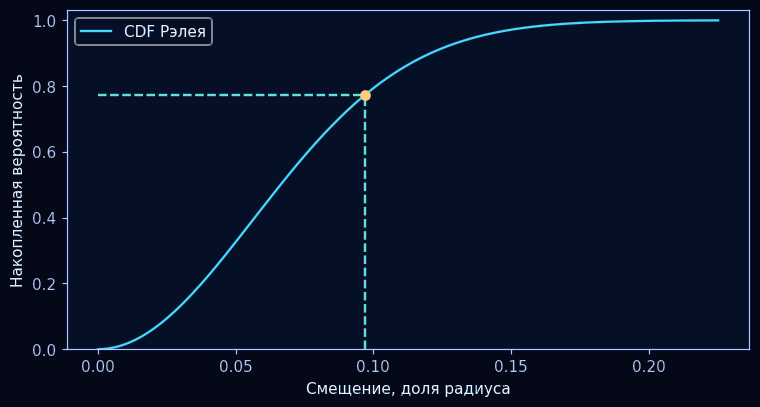

In [71]:
# @title Одно случайное число на графике { run: "auto" }
seed = 42 # @param {type:"integer"}
u = np.random.default_rng(seed).random()
value = sigma_hat * np.sqrt(-2 * np.log1p(-u))
grid = np.linspace(0, max(4*sigma_hat, value*1.1), 400)
cdf = -np.expm1(-grid**2 / (2*sigma_hat**2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, cdf, color=SPACE_COLORS["cyan"], linewidth=1.8, label="CDF Рэлея")
ax.hlines(u, 0, value, linestyle="--", color=SPACE_COLORS["mint"])
ax.vlines(value, 0, u, linestyle="--", color=SPACE_COLORS["mint"])
ax.scatter(value, u, color=SPACE_COLORS["gold"], s=42, zorder=3)
ax.set(xlabel="Смещение, доля радиуса", ylabel="Накопленная вероятность", ylim=(0, 1.03))
ax.legend()
style_axis(ax)
plt.show()
print(f"u = {u:.6f}; смещение = {value:.6f}; проверка F(смещение) = {-np.expm1(-value**2/(2*sigma_hat**2)):.6f}")


**Проверка обратного преобразования.** При seed 42 получилось $u=0{,}773956$. По пунктиру считываем смещение около 0,0971 радиуса. Подставляем его обратно в функцию распределения и получаем исходное $u$ с указанной точностью.


<a id="appstat-sprint2-criteria"></a>

### 02.2. cat_mark_table


| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| lab.de.01 | [Сравнение с данными](#scrollTo=6ecd79117445) | | Гистограмма, накопленные доли и сводка метрик |
| lab.de.01 | [Проверка одного числа](#scrollTo=9ec3810d4184) | | Интерактивная проверка метода обратной функции |
| lab.de.01 | [Метод обратной функции](#scrollTo=5a8b90fff112) | | Формула в LaTeX и ссылка на материал по генератору |


<a id="appstat-sources"></a>

## Источники

- [APPSTAT-LABWORK](https://github.com/SanechkaTuoKe/APPSTAT-LABWORK) — подготовка признаков WM-811K и анализ трёх величин.
- NIST Dataplot. Распределение Рэлея: [функция распределения](https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/raycdf.htm) и [обратная функция](https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/rayppf.htm).
- [WM-811K wafer map — карточка исходного набора данных на Kaggle](https://www.kaggle.com/datasets/qingyi/wm811k-wafer-map) — источник набора WM-811K; в этой работе анализируется выбранная подвыборка и признаки, подготовленные командой.
- Wu, M.-J., Jang, J.-S. R., Chen, J.-L. (2015). *Wafer Map Failure Pattern Recognition and Similarity Ranking for Large-Scale Data Sets*. IEEE Transactions on Semiconductor Manufacturing, 28(1), 1–12. [DOI: 10.1109/TSM.2014.2364237](https://doi.org/10.1109/TSM.2014.2364237).
